# Rivals on the Map: how cartel co-presence shapes the expansion and retreat of Mexican drug trafficking organizations, 1990–2010

**Research question: Does the presence of rival cartels predict where cartel–municipality links form and where they disappear?**

Each annual graph is an **undirected, unweighted bipartite network**: municipality nodes connect to organization/category nodes when the CSV entry equals 1. Edges represent reported associations, not proof of territorial control or cooperation. `Otros` is retained as an aggregate category, not interpreted as one cartel.

`networks_by_year` stores all annual snapshots. **`net` is the 2010 snapshot** by default; change `selected_year` to explore another year. All municipalities recorded in that year and all ten categories are included, even when isolated. Years are not pooled.

Explicit annual variables `net_1990` through `net_2010` reference the same graphs as `networks_by_year`.

In [1]:
from pathlib import Path

import pandas as pd
import networkx as nx
from networkx.algorithms import bipartite
from IPython.display import display

# Run the notebook with its containing directory as the working directory.
data = pd.read_csv(
    Path("CosciaRios2012_DataBase.csv"),
    dtype={"Code": "string", "State": "string"},
)
organization_columns = data.columns.drop(["Code", "State", "Year"]).tolist()
assert not data.isna().any().any(), "Missing values require inspection."
assert not data.duplicated(["Code", "Year"]).any(), "Duplicate municipality-year rows."
assert data[organization_columns].isin([0, 1]).all().all(), "Expected binary associations."

print(f"Records: {len(data):,}")
print(f"Years: {data['Year'].min()}–{data['Year'].max()}")
print(f"Distinct municipalities: {data['Code'].nunique():,}")
print(f"Organization/category columns: {len(organization_columns)}")

Records: 51,596
Years: 1990–2010
Distinct municipalities: 2,457
Organization/category columns: 10


In [2]:
def build_annual_network(year_data, year):
    graph = nx.Graph(year=int(year))
    # Prefixes prevent collisions between municipality and organization identifiers.
    graph.add_nodes_from(
        (f"organization:{name}", {"bipartite": 1, "node_type": "organization", "label": name})
        for name in organization_columns
    )
    for _, row in year_data.iterrows():
        municipality = f"municipality:{row['Code']}"
        graph.add_node(
            municipality, bipartite=0, node_type="municipality",
            code=row["Code"], state=row["State"], label=row["Code"],
        )
        graph.add_edges_from(
            (municipality, f"organization:{name}")
            for name in organization_columns if row[name] == 1
        )
    return graph

networks_by_year = {
    int(year): build_annual_network(year_data, year)
    for year, year_data in data.groupby("Year", sort=True)
}
net_1990 = networks_by_year[1990]
net_1991 = networks_by_year[1991]
net_1992 = networks_by_year[1992]
net_1993 = networks_by_year[1993]
net_1994 = networks_by_year[1994]
net_1995 = networks_by_year[1995]
net_1996 = networks_by_year[1996]
net_1997 = networks_by_year[1997]
net_1998 = networks_by_year[1998]
net_1999 = networks_by_year[1999]
net_2000 = networks_by_year[2000]
net_2001 = networks_by_year[2001]
net_2002 = networks_by_year[2002]
net_2003 = networks_by_year[2003]
net_2004 = networks_by_year[2004]
net_2005 = networks_by_year[2005]
net_2006 = networks_by_year[2006]
net_2007 = networks_by_year[2007]
net_2008 = networks_by_year[2008]
net_2009 = networks_by_year[2009]
net_2010 = networks_by_year[2010]

selected_year = 2010
net = networks_by_year[selected_year]
municipality_nodes = {n for n, attrs in net.nodes(data=True) if attrs["bipartite"] == 0}
organization_nodes = set(net) - municipality_nodes

assert nx.is_bipartite(net)
assert all(net.nodes[u]["bipartite"] != net.nodes[v]["bipartite"] for u, v in net.edges())
print(f"net: {selected_year} annual snapshot")

net: 2010 annual snapshot


## Basic statistics

Standard NetworkX density uses all possible pairs of nodes. Bipartite density instead uses only possible municipality–organization pairs, making it more informative here. Average degree includes isolated nodes; active municipalities have at least one reported association. Clustering below is ordinary triangle clustering, which is necessarily zero in a bipartite graph.

Distances are reported only within the largest connected component because disconnected networks have no finite overall average shortest path.

In [3]:
def basic_stats(graph):
    municipalities = {n for n, attrs in graph.nodes(data=True) if attrs["bipartite"] == 0}
    organizations = set(graph) - municipalities
    components = list(nx.connected_components(graph))
    largest = max(components, key=len, default=set())
    n, m = graph.number_of_nodes(), graph.number_of_edges()
    return {
        "nodes": n,
        "municipalities": len(municipalities),
        "organization_categories": len(organizations),
        "edges": m,
        "active_municipalities": sum(graph.degree(v) > 0 for v in municipalities),
        "active_organization_categories": sum(graph.degree(v) > 0 for v in organizations),
        "isolates": nx.number_of_isolates(graph),
        "connected_components": len(components),
        "largest_component_nodes": len(largest),
        "average_degree": 2 * m / n if n else 0,
        "density": nx.density(graph),
        "bipartite_density": bipartite.density(graph, municipalities),
    }

stats = pd.Series(basic_stats(net), name=selected_year)
display(stats.to_frame("value"))

largest_component = net.subgraph(max(nx.connected_components(net), key=len)).copy()
print(f"Bipartite: {nx.is_bipartite(net)}")
print(f"Connected: {nx.is_connected(net)}")
print(f"Average triangle clustering: {nx.average_clustering(net):.3f}")
print(f"Largest component diameter: {nx.diameter(largest_component)}")
print(
    "Largest component average shortest path length: "
    f"{nx.average_shortest_path_length(largest_component):.3f}"
)

,value
nodes,2466.000000
municipalities,2456.000000
organization_categories,10.000000
edges,1486.000000
active_municipalities,709.000000
active_organization_categories,10.000000
isolates,1747.000000
connected_components,1748.000000
largest_component_nodes,719.000000
average_degree,1.205191


Bipartite: True
Connected: False
Average triangle clustering: 0.000
Largest component diameter: 4
Largest component average shortest path length: 2.888


In [4]:
# Organization degree is the number of associated municipalities in this year.
organization_degrees = pd.DataFrame([
    {"organization_category": net.nodes[node]["label"], "municipalities": net.degree(node)}
    for node in organization_nodes
]).sort_values(["municipalities", "organization_category"], ascending=[False, True]).reset_index(drop=True)
display(organization_degrees)

# Municipality degree is the number of associated organization categories.
municipality_degree_counts = pd.Series(
    [net.degree(node) for node in municipality_nodes], name="municipalities"
).value_counts().sort_index().rename_axis("organization_categories")
display(municipality_degree_counts.to_frame())

,organization_category,municipalities
0,Zetas,405
1,Golfo,244
2,Familia,227
3,Sinaloa,176
4,Beltran_Leyva,157
5,Juarez,74
6,Beltran_Leyva_Family,57
7,Otros,54
8,Sinaloa_Family,53
9,Tijuana,39


,count
organization_categories,
0,1747
1,271
2,261
3,86
4,50
5,22
6,11
7,6
8,1


In [5]:
annual_stats = pd.DataFrame.from_dict(
    {year: basic_stats(graph) for year, graph in networks_by_year.items()},
    orient="index",
).rename_axis("year")
display(annual_stats)
print(f"Mean annual nodes: {annual_stats['nodes'].mean():,.1f}")
print(f"Mean annual edges: {annual_stats['edges'].mean():,.1f}")
print(f"Total associations across municipality-year records: {annual_stats['edges'].sum():,}")

,nodes,municipalities,organization_categories,edges,active_municipalities,active_organization_categories,isolates,connected_components,largest_component_nodes,average_degree,density,bipartite_density
year,,,,,,,,,,,,
1990,2467,2457,10,0,0,0,2467,2467,1,0.000000,0.000000,0.000000
1991,2467,2457,10,6,6,2,2459,2461,4,0.004864,0.000002,0.000244
1992,2467,2457,10,6,5,3,2459,2461,6,0.004864,0.000002,0.000244
1993,2467,2457,10,24,22,5,2440,2443,15,0.019457,0.000008,0.000977
1994,2467,2457,10,31,29,4,2434,2436,30,0.025132,0.000010,0.001262
1995,2467,2457,10,23,20,4,2443,2445,16,0.018646,0.000008,0.000936
1996,2467,2457,10,36,31,6,2430,2432,35,0.029185,0.000012,0.001465
1997,2467,2457,10,51,48,6,2413,2417,25,0.041346,0.000017,0.002076
1998,2467,2457,10,49,43,5,2419,2420,48,0.039724,0.000016,0.001994


Mean annual nodes: 2,467.0
Mean annual edges: 296.6
Total associations across municipality-year records: 6,228


## 2010 network plot

Orange nodes represent organization categories; blue nodes represent municipalities. All active nodes appear in the main panel; all isolated municipalities appear separately for readability. Only organization categories are labeled. Layout positions represent network structure, not geography; isolate positions are arbitrary.

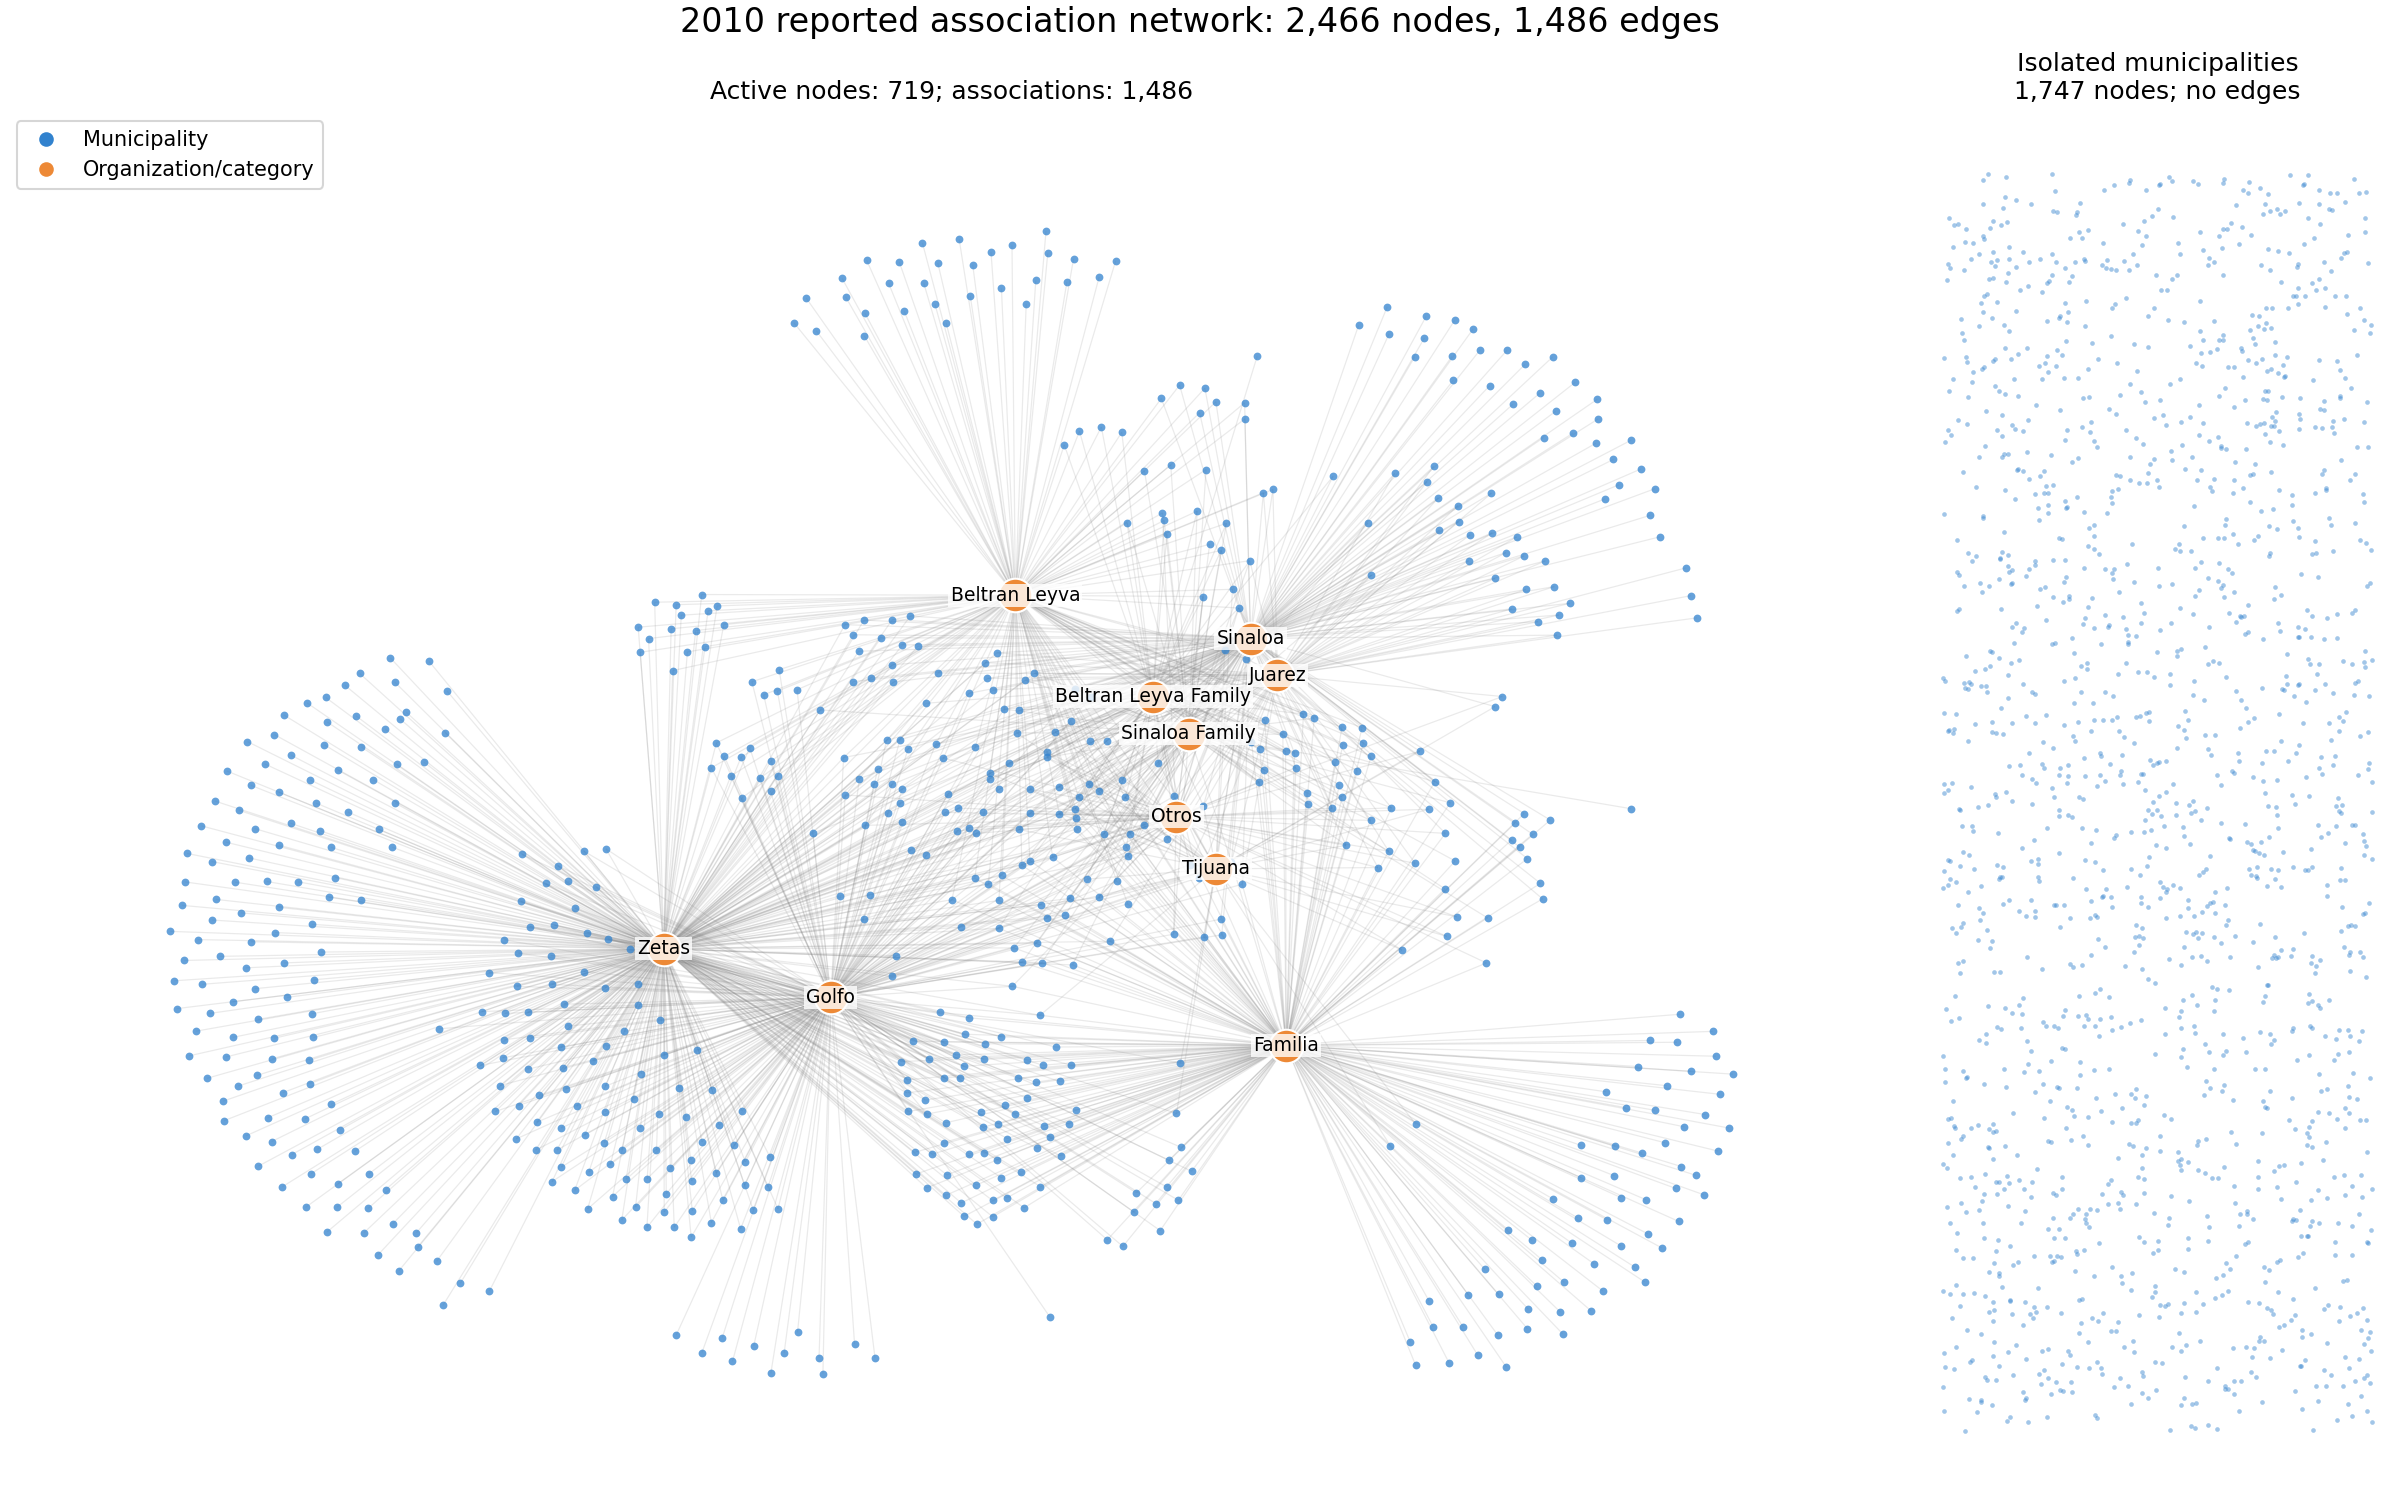

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from IPython.display import Image
from io import BytesIO

plot_net = net_2010
isolates = list(nx.isolates(plot_net))
active = plot_net.subgraph([n for n in plot_net if plot_net.degree(n) > 0])
organizations = sorted(n for n in active if active.nodes[n]["bipartite"] == 1)
municipalities = sorted(set(active) - set(organizations))
pos = nx.spring_layout(active, seed=42, iterations=150)
fig, (ax, ax_isolates) = plt.subplots(1, 2, figsize=(16, 10),
    gridspec_kw={"width_ratios": [4, 1]}, constrained_layout=True)
nx.draw_networkx_edges(active, pos, ax=ax, edge_color="gray", alpha=0.16, width=0.6)
nx.draw_networkx_nodes(active, pos, nodelist=municipalities, ax=ax,
    node_color="#3182ce", node_size=14, alpha=0.75, linewidths=0)
nx.draw_networkx_nodes(active, pos, nodelist=organizations, ax=ax,
    node_color="#ed8936", node_size=260, edgecolors="white")
nx.draw_networkx_labels(active, pos, ax=ax, font_size=9,
    labels={n: active.nodes[n]["label"].replace("_", " ") for n in organizations},
    bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 1})
ax.set_title(f"Active nodes: {len(active):,}; associations: {active.number_of_edges():,}")
ax.legend(handles=[Line2D([], [], marker="o", linestyle="", color=color, label=label)
    for color, label in [("#3182ce", "Municipality"), ("#ed8936", "Organization/category")]],
    loc="upper left")
ax.axis("off")
rng = np.random.default_rng(42)
isolate_pos = dict(zip(isolates, rng.random((len(isolates), 2))))
nx.draw_networkx_nodes(plot_net, isolate_pos, nodelist=isolates, ax=ax_isolates,
    node_color="#3182ce", node_size=5, alpha=0.45, linewidths=0)
ax_isolates.set_title(f"Isolated municipalities\n{len(isolates):,} nodes; no edges")
ax_isolates.axis("off")
fig.suptitle(f"2010 reported association network: {len(plot_net):,} nodes, "
    f"{plot_net.number_of_edges():,} edges", fontsize=16)
# Embed the plot without creating a separate image file.
plot_buffer = BytesIO()
fig.savefig(plot_buffer, format="png", dpi=150)
plt.close(fig)
display(Image(data=plot_buffer.getvalue()))

## Descriptive statistics for the presentation

Describe recorded associations rather than territorial control. Organization degree measures associated municipalities; municipality degree measures associated organization categories. Municipality overlap means at least two categories are recorded in the same municipality, not evidence of cooperation or rivalry.

Coverage and edge turnover are reported separately. Turnover comparisons use only municipalities recorded in **both adjacent years**, so entering or leaving the file does not automatically count as link formation or disappearance. “Appearing” means absent in the previous snapshot, including possible reappearances. The first year has no previous snapshot and therefore no turnover estimate.

In [7]:
# Add presentation measures to the annual summary.
for year, graph in networks_by_year.items():
    municipalities = [n for n in graph if graph.nodes[n]["bipartite"] == 0]
    degrees = [graph.degree(n) for n in municipalities]
    active_count = sum(d > 0 for d in degrees)
    overlap_count = sum(d >= 2 for d in degrees)
    annual_stats.loc[year, "active_municipality_percentage"] = 100 * active_count / len(municipalities)
    annual_stats.loc[year, "overlapping_municipalities"] = overlap_count
    annual_stats.loc[year, "overlap_percentage_among_active"] = 100 * overlap_count / active_count if active_count else 0
    annual_stats.loc[year, "mean_degree_active_municipalities"] = sum(degrees) / active_count if active_count else 0

def municipality_set(graph):
    return {n for n, attrs in graph.nodes(data=True) if attrs["bipartite"] == 0}

def association_set(graph, municipalities):
    return {(municipality, organization)
            for municipality in municipalities for organization in graph.neighbors(municipality)}

turnover_records = []
years = sorted(networks_by_year)
for previous_year, year in zip(years[:-1], years[1:]):
    previous_graph, current_graph = networks_by_year[previous_year], networks_by_year[year]
    previous_municipalities = municipality_set(previous_graph)
    current_municipalities = municipality_set(current_graph)
    shared = previous_municipalities & current_municipalities
    previous_edges = association_set(previous_graph, shared)
    current_edges = association_set(current_graph, shared)
    turnover_records.append({
        "year": year,
        "shared_municipalities": len(shared),
        "municipalities_entering_file": len(current_municipalities - previous_municipalities),
        "municipalities_leaving_file": len(previous_municipalities - current_municipalities),
        "appearing_associations": len(current_edges - previous_edges),
        "persisting_associations": len(current_edges & previous_edges),
        "disappearing_associations": len(previous_edges - current_edges),
        "associations_in_entering_municipalities": len(association_set(current_graph, current_municipalities - previous_municipalities)),
        "associations_in_leaving_municipalities": len(association_set(previous_graph, previous_municipalities - current_municipalities)),
    })
turnover_stats = pd.DataFrame(turnover_records).set_index("year")
display(annual_stats)
display(turnover_stats)

# Named variables used in the presentation.
dataset_summary = {
    "First year": min(years), "Last year": max(years), "Annual snapshots": len(years),
    "Municipality-year records": len(data), "Distinct municipalities across all years": data["Code"].nunique(),
    "Organization categories": len(organization_columns),
    "Total associations across all years": int(annual_stats["edges"].sum()),
    "Mean annual nodes": annual_stats["nodes"].mean(),
    "Mean annual edges": annual_stats["edges"].mean(),
}
snapshot_2010_stats = basic_stats(net_2010)
snapshot_2010_stats.update({
    name: annual_stats.loc[2010, name]
    for name in ["active_municipality_percentage", "overlapping_municipalities",
                 "overlap_percentage_among_active", "mean_degree_active_municipalities"]
})
component_2010 = net_2010.subgraph(max(nx.connected_components(net_2010), key=len))
snapshot_2010_stats["largest_component_diameter"] = nx.diameter(component_2010)
snapshot_2010_stats["largest_component_mean_shortest_path"] = nx.average_shortest_path_length(component_2010)
organization_degrees_2010 = pd.Series({net_2010.nodes[n]["label"]: net_2010.degree(n)
    for n in net_2010 if net_2010.nodes[n]["bipartite"] == 1}).sort_values(ascending=False)
municipality_degree_counts_2010 = pd.Series([net_2010.degree(n) for n in municipality_set(net_2010)]
    ).value_counts().sort_index().rename_axis("organization_categories")

,nodes,municipalities,organization_categories,edges,active_municipalities,active_organization_categories,isolates,connected_components,largest_component_nodes,average_degree,density,bipartite_density,active_municipality_percentage,overlapping_municipalities,overlap_percentage_among_active,mean_degree_active_municipalities
year,,,,,,,,,,,,,,,,
1990,2467,2457,10,0,0,0,2467,2467,1,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000
1991,2467,2457,10,6,6,2,2459,2461,4,0.004864,0.000002,0.000244,0.244200,0.0,0.000000,1.000000
1992,2467,2457,10,6,5,3,2459,2461,6,0.004864,0.000002,0.000244,0.203500,1.0,20.000000,1.200000
1993,2467,2457,10,24,22,5,2440,2443,15,0.019457,0.000008,0.000977,0.895401,2.0,9.090909,1.090909
1994,2467,2457,10,31,29,4,2434,2436,30,0.025132,0.000010,0.001262,1.180301,2.0,6.896552,1.068966
1995,2467,2457,10,23,20,4,2443,2445,16,0.018646,0.000008,0.000936,0.814001,3.0,15.000000,1.150000
1996,2467,2457,10,36,31,6,2430,2432,35,0.029185,0.000012,0.001465,1.261701,5.0,16.129032,1.161290
1997,2467,2457,10,51,48,6,2413,2417,25,0.041346,0.000017,0.002076,1.953602,3.0,6.250000,1.062500
1998,2467,2457,10,49,43,5,2419,2420,48,0.039724,0.000016,0.001994,1.750102,6.0,13.953488,1.139535


,shared_municipalities,municipalities_entering_file,municipalities_leaving_file,appearing_associations,persisting_associations,disappearing_associations,associations_in_entering_municipalities,associations_in_leaving_municipalities
year,,,,,,,,
1991,2457,0,0,6,0,0,0,0
1992,2457,0,0,6,0,6,0,0
1993,2457,0,0,21,3,3,0,0
1994,2457,0,0,25,6,18,0,0
1995,2457,0,0,15,8,23,0,0
1996,2457,0,0,28,8,15,0,0
1997,2457,0,0,42,9,27,0,0
1998,2457,0,0,37,12,39,0,0
1999,2457,0,0,24,7,42,0,0


## Presentation figures

Counts show changes in recorded coverage and associations. Turnover is restricted to shared municipalities. `Otros` remains an aggregate category. Figures are embedded in the notebook; no separate files are saved.

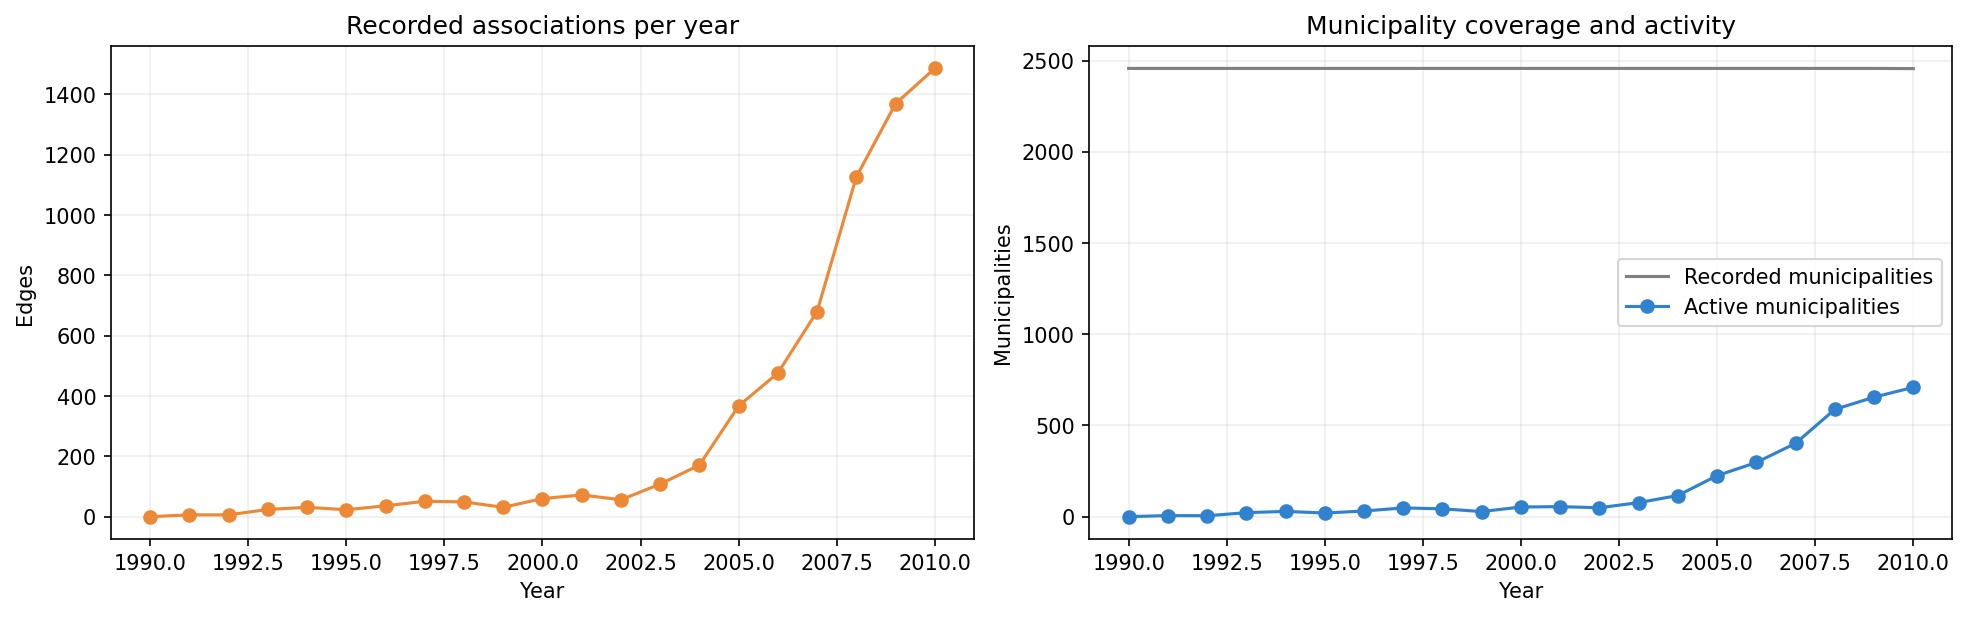

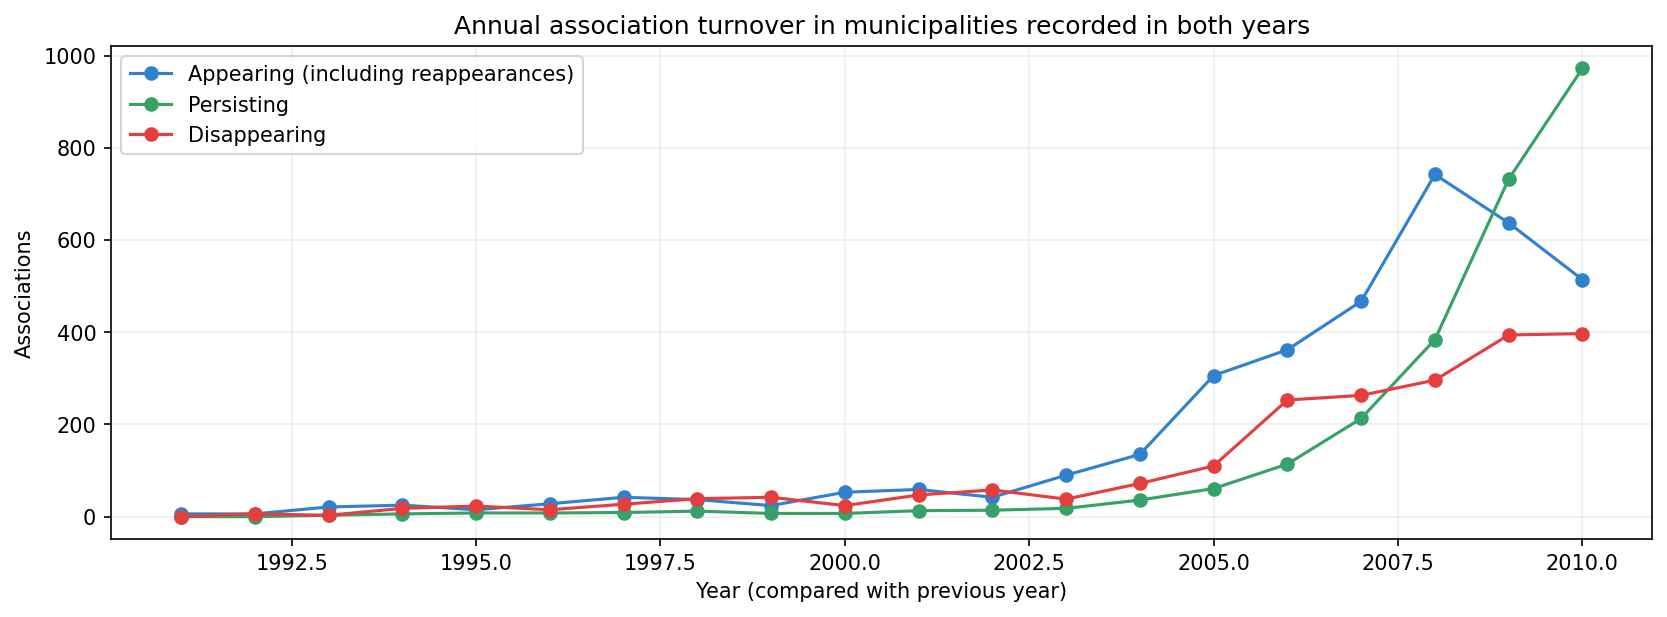

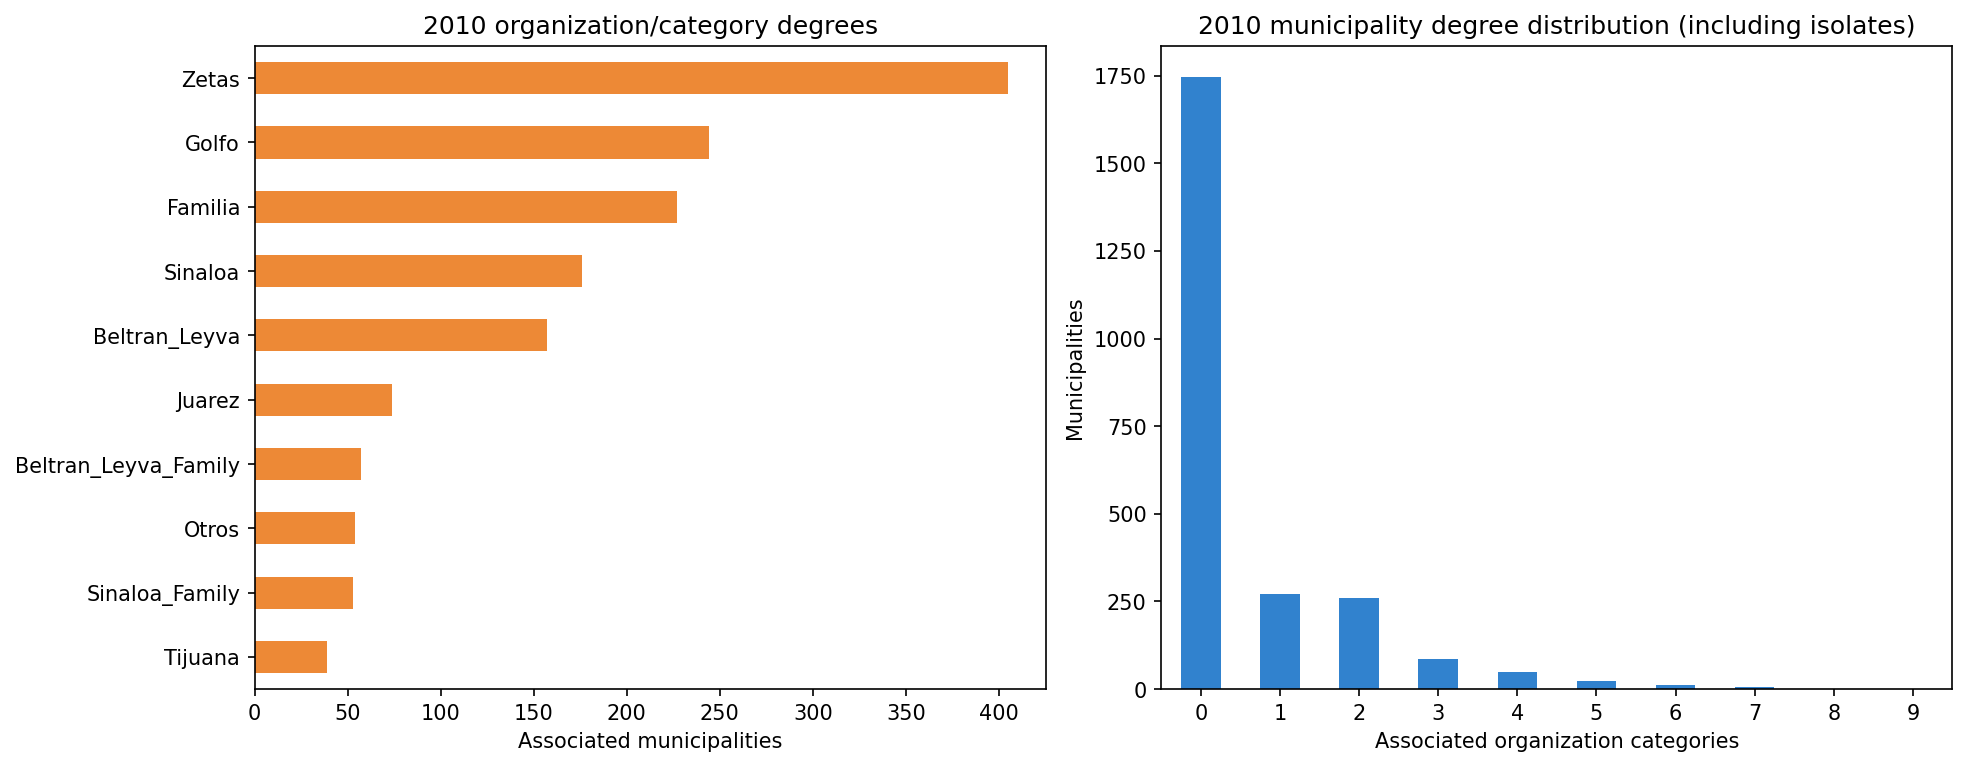

In [8]:
def show_presentation_figure(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=150, bbox_inches="tight")
    plt.close(fig)
    display(Image(data=buffer.getvalue()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
axes[0].plot(annual_stats.index, annual_stats["edges"], marker="o", color="#ed8936")
axes[0].set(title="Recorded associations per year", xlabel="Year", ylabel="Edges")
axes[1].plot(annual_stats.index, annual_stats["municipalities"], label="Recorded municipalities", color="gray")
axes[1].plot(annual_stats.index, annual_stats["active_municipalities"], marker="o", label="Active municipalities", color="#3182ce")
axes[1].set(title="Municipality coverage and activity", xlabel="Year", ylabel="Municipalities")
axes[1].legend()
for ax in axes: ax.grid(alpha=0.2)
show_presentation_figure(fig)

fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
for column, label, color in [
    ("appearing_associations", "Appearing (including reappearances)", "#3182ce"),
    ("persisting_associations", "Persisting", "#38a169"),
    ("disappearing_associations", "Disappearing", "#e53e3e"),
]:
    ax.plot(turnover_stats.index, turnover_stats[column], marker="o", label=label, color=color)
ax.set(title="Annual association turnover in municipalities recorded in both years",
       xlabel="Year (compared with previous year)", ylabel="Associations")
ax.legend()
ax.grid(alpha=0.2)
show_presentation_figure(fig)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
organization_degrees_2010.sort_values().plot.barh(ax=axes[0], color="#ed8936")
axes[0].set(title="2010 organization/category degrees", xlabel="Associated municipalities", ylabel="")
municipality_degree_counts_2010.plot.bar(ax=axes[1], color="#3182ce", rot=0)
axes[1].set(title="2010 municipality degree distribution (including isolates)",
    xlabel="Associated organization categories", ylabel="Municipalities")
show_presentation_figure(fig)

## The network over time

Summary of how the organization side of the network changed. The Herfindahl–Hirschman index (HHI) of organization degree shares measures concentration: 1 means a single organization holds every association; 1/k means k organizations share them equally. The share of active municipalities with two or more organizations measures overlap. Because recorded associations grow sharply (mostly reporting), these measures describe the recorded network rather than proving centralization or fragmentation. The fixed set of ten categories also means the data cannot show new organizations splitting off.

,active_organizations,active_municipalities,share_multi_organization,mean_organizations_per_active_municipality,largest_organization_share,organization_concentration_hhi
year,,,,,,
1991,2,6,0.000,1.000,0.500,0.500
1992,3,5,0.200,1.200,0.500,0.389
1993,5,22,0.091,1.091,0.500,0.337
1994,4,29,0.069,1.069,0.419,0.322
1995,4,20,0.150,1.150,0.304,0.263
1996,6,31,0.161,1.161,0.306,0.256
1997,6,48,0.062,1.062,0.373,0.267
1998,5,43,0.140,1.140,0.367,0.240
1999,5,28,0.107,1.107,0.355,0.257


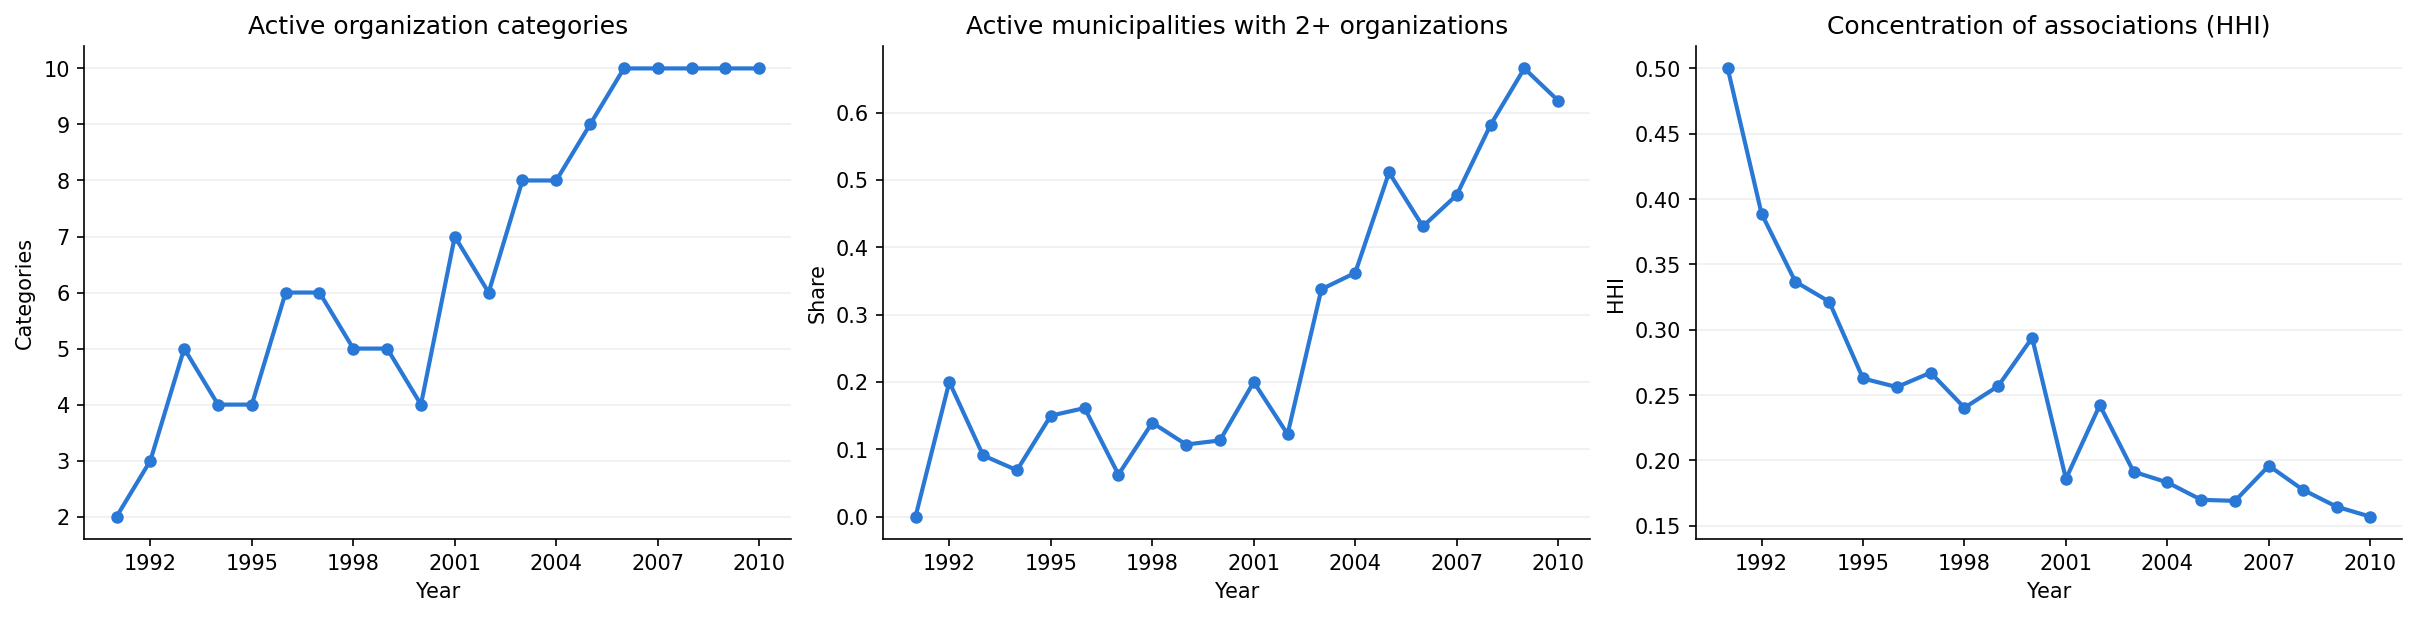

In [9]:
over_time_rows = []
for year, rows in data.groupby("Year"):
    matrix = rows[organization_columns].to_numpy()
    active = matrix[matrix.sum(axis=1) > 0]
    organization_degree = matrix.sum(axis=0)
    if organization_degree.sum() == 0:
        continue
    shares = organization_degree / organization_degree.sum()
    over_time_rows.append({
        "year": int(year),
        "active_organizations": int((organization_degree > 0).sum()),
        "active_municipalities": len(active),
        "share_multi_organization": (active.sum(axis=1) > 1).mean(),
        "mean_organizations_per_active_municipality": active.sum(axis=1).mean(),
        "largest_organization_share": shares.max(),
        "organization_concentration_hhi": (shares ** 2).sum(),
    })
network_over_time = pd.DataFrame(over_time_rows).set_index("year")
display(network_over_time.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
panels = [
    ("active_organizations", "Active organization categories", "Categories"),
    ("share_multi_organization", "Active municipalities with 2+ organizations", "Share"),
    ("organization_concentration_hhi", "Concentration of associations (HHI)", "HHI"),
]
for ax, (column, title, ylabel) in zip(axes, panels):
    ax.plot(network_over_time.index, network_over_time[column], color="#2a78d6", lw=2, marker="o", ms=5)
    ax.set(title=title, xlabel="Year", ylabel=ylabel)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
show_presentation_figure(fig)

## Presentation values: Name : value

The following cell prints every numerical descriptive measure used above, including the full annual and turnover tables. Percentages use a 0–100 scale. Graph objects, layout coordinates, and temporary plotting variables are not presentation statistics.

In [10]:
def print_presentation_value(name, value):
    if isinstance(value, (int, np.integer)):
        formatted = str(value)
    elif isinstance(value, (float, np.floating)):
        formatted = str(int(value)) if float(value).is_integer() else f"{value:.6g}"
    else:
        formatted = str(value)
    print(f"{name} : {formatted}")

for name, value in dataset_summary.items():
    print_presentation_value(name, value)
for name, value in snapshot_2010_stats.items():
    print_presentation_value(f"2010 {name.replace('_', ' ')}", value)
for organization, degree in organization_degrees_2010.items():
    print_presentation_value(f"2010 {organization} degree", degree)
for degree, count in municipality_degree_counts_2010.items():
    print_presentation_value(f"2010 municipalities with degree {degree}", count)
for year, row in annual_stats.iterrows():
    for name, value in row.items():
        print_presentation_value(f"{year} {name.replace('_', ' ')}", value)
for year, row in turnover_stats.iterrows():
    for name, value in row.items():
        print_presentation_value(f"{year} {name.replace('_', ' ')}", value)

First year : 1990
Last year : 2010
Annual snapshots : 21
Municipality-year records : 51596
Distinct municipalities across all years : 2457
Organization categories : 10
Total associations across all years : 6228
Mean annual nodes : 2466.95
Mean annual edges : 296.571
2010 nodes : 2466
2010 municipalities : 2456
2010 organization categories : 10
2010 edges : 1486
2010 active municipalities : 709
2010 active organization categories : 10
2010 isolates : 1747
2010 connected components : 1748
2010 largest component nodes : 719
2010 average degree : 1.20519
2010 density : 0.000488921
2010 bipartite density : 0.0605049
2010 active municipality percentage : 28.8681
2010 overlapping municipalities : 438
2010 overlap percentage among active : 61.7772
2010 mean degree active municipalities : 2.09591
2010 largest component diameter : 4
2010 largest component mean shortest path : 2.88777
2010 Zetas degree : 405
2010 Golfo degree : 244
2010 Familia degree : 227
2010 Sinaloa degree : 176
2010 Beltran_

# Research question

**Does the presence of rival cartels predict where cartel–municipality links form and where they disappear?**

Hypotheses:

- **H1 (path dependence):** a new association is more likely where the organization is already present elsewhere in the same state.
- **H2 (rival deterrence):** a new association is less likely where the municipality already hosts an organization that the focal organization significantly avoids.
- **H3 (displacement):** an existing association is more likely to disappear the next year when an avoiding rival is present in the same municipality.
- **H4 (heterogeneity):** these patterns differ between organizations.

Analysis plan:

1. **Rivalry scores from null models.** Project the bipartite network onto organizations and compare each pair's overlap with degree-preserving and state-stratified random networks. The yearly z-scores define which organizations avoid or overlap each other.
2. **H1:** formation rates inside versus outside states where the organization is present.
3. **H2 (formation):** temporal link prediction with history, structural and territorial features; rate tables and a state-clustered GLM.
4. **H3 (disappearance):** the same design for associations present at *t* that are absent at *t+1*.
5. **H4:** organization-by-organization breakdown.
6. **Robustness** (excluding `Otros`, first-observed links only), then a descriptive mesoscale view (backbone and communities).

Outcomes are changes in **recorded** associations, not confirmed expansion or retreat. A recorded disappearance can mean the organization left, lost a conflict, or simply stopped being reported. Results are conditional associations, not causal effects.

## Step 1: rivalry scores from null models

The methods follow the course material:

- **Bipartite projection** (Lecture 5): organization–organization overlap is the number of municipalities associated with both organizations.
- **Null models** (Lecture 4): a configuration-model-style null for bipartite graphs (curveball sampling) keeps every municipality's and every organization's degree fixed. A second, **state-stratified** null only exchanges associations between municipalities of the same state, so it also keeps each organization's count in every state fixed. Overlap beyond the stratified null cannot be explained by two organizations simply operating in the same states.

A positive overlap means two categories are *recorded in the same municipalities more than chance*; it can reflect alliance, a split from a common parent, or a contested territory. A negative overlap means avoidance or separate territories.

Only **active** municipalities (at least one association in that year) are used. The figures show three focus years: 2006 (start of the federal offensive), 2008 (Beltrán Leyva split from Sinaloa) and 2010 (Zetas split from the Gulf cartel). The yearly state-stratified z-scores for every year are computed at the end of this step and reused as predictors.

In [11]:
from scipy.stats import norm
from sklearn.metrics import normalized_mutual_info_score
from matplotlib.colors import LinearSegmentedColormap

focus_years = [2006, 2008, 2010]
null_samples = 300
display_names = {
    "Beltran_Leyva": "Beltrán Leyva", "Beltran_Leyva_Family": "BL Family", "Familia": "Familia",
    "Golfo": "Gulf", "Juarez": "Juárez", "Sinaloa": "Sinaloa", "Sinaloa_Family": "Sinaloa Family",
    "Tijuana": "Tijuana", "Zetas": "Zetas", "Otros": "Otros",
}
# INEGI state codes, used only for readable labels.
state_names = dict(enumerate([
    "Aguascalientes", "Baja California", "Baja California Sur", "Campeche", "Coahuila", "Colima",
    "Chiapas", "Chihuahua", "Distrito Federal", "Durango", "Guanajuato", "Guerrero", "Hidalgo",
    "Jalisco", "México", "Michoacán", "Morelos", "Nayarit", "Nuevo León", "Oaxaca", "Puebla",
    "Querétaro", "Quintana Roo", "San Luis Potosí", "Sinaloa", "Sonora", "Tabasco", "Tamaulipas",
    "Tlaxcala", "Veracruz", "Yucatán", "Zacatecas",
], start=1))
state_names = {str(code): name for code, name in state_names.items()}
# Diverging scale: blue = less overlap than chance, neutral gray = as expected, red = more.
diverging_cmap = LinearSegmentedColormap.from_list("blue_gray_red", ["#1c5cab", "#f0efec", "#c23434"])

def active_records(year):
    year_data = data[data["Year"] == year]
    return year_data[year_data[organization_columns].sum(axis=1) > 0].reset_index(drop=True)

active_by_year = {year: active_records(year) for year in focus_years}
for year, records in active_by_year.items():
    print(f"{year}: {len(records)} active municipalities in {records['State'].nunique()} states")

2006: 297 active municipalities in 31 states
2008: 588 active municipalities in 32 states
2010: 709 active municipalities in 32 states


## Organization projection against two null models

Observed overlap between organizations *a* and *b* is the number of active municipalities associated with both (the weighted organization projection). Each null sample is a random bipartite graph with the same degrees, generated with the curveball algorithm (Strona et al. 2014). The z-score compares observed overlap with the null mean and standard deviation over the samples.

With 45 organization pairs per year, a pair is called significant only when |z| exceeds the two-sided Bonferroni threshold for α = 0.05.

In [12]:
def curveball_sample(matrix, groups, rng, trades_per_row=5):
    """Random bipartite graph with the same row and column degrees as `matrix`.

    Rows trade associations only with rows in the same group, so per-group column
    totals are also preserved. Use a single group for the plain degree-preserving null.
    """
    rows = [set(np.flatnonzero(row)) for row in matrix]
    members = [np.flatnonzero(groups == g) for g in np.unique(groups)]
    members = [m for m in members if len(m) > 1]
    if not members:
        return matrix.copy()
    sizes = np.array([len(m) for m in members])
    n_trades = trades_per_row * len(rows)
    # Choosing groups proportionally to size makes each trade roughly a uniform row pair.
    picked = rng.choice(len(members), size=n_trades, p=sizes / sizes.sum())
    first = rng.random(n_trades)
    second = rng.random(n_trades)
    for g, u, v in zip(picked, first, second):
        m = members[g]
        a = int(u * len(m))
        b = int(v * (len(m) - 1))
        b += b >= a
        i, j = m[a], m[b]
        only_i, only_j = rows[i] - rows[j], rows[j] - rows[i]
        if not only_i or not only_j:
            continue
        shared = rows[i] & rows[j]
        pool = list(only_i | only_j)
        rng.shuffle(pool)
        rows[i] = shared | set(pool[:len(only_i)])
        rows[j] = shared | set(pool[len(only_i):])
    sample = np.zeros_like(matrix)
    for i, row in enumerate(rows):
        sample[i, list(row)] = 1
    return sample

def overlap_zscores(records, stratify_by_state, seed):
    rng = np.random.default_rng(seed)
    matrix = records[organization_columns].to_numpy()
    if len(records) < 2:
        zeros = pd.DataFrame(0.0, index=organization_columns, columns=organization_columns)
        return zeros, matrix.T @ matrix
    groups = records["State"].to_numpy() if stratify_by_state else np.zeros(len(records), dtype=int)
    observed = matrix.T @ matrix
    samples = []
    for _ in range(null_samples):
        sample = curveball_sample(matrix, groups, rng)
        samples.append(sample.T @ sample)
    samples = np.array(samples)
    mean, sd = samples.mean(axis=0), samples.std(axis=0)
    # A pair whose overlap cannot vary under the null gets z = 0 rather than a division by zero.
    z = np.where(sd > 0, (observed - mean) / np.where(sd > 0, sd, 1), 0.0)
    np.fill_diagonal(z, 0)
    return pd.DataFrame(z, index=organization_columns, columns=organization_columns), observed

n_pairs = len(organization_columns) * (len(organization_columns) - 1) // 2
critical_z = norm.isf(0.05 / (2 * n_pairs))
print(f"Bonferroni critical |z| for {n_pairs} pairs: {critical_z:.2f}")

overlap_z = {}
overlap_observed = {}
for k, year in enumerate(focus_years):
    records = active_by_year[year]
    overlap_z[(year, "degree")], overlap_observed[year] = overlap_zscores(records, False, seed=k)
    overlap_z[(year, "state")], _ = overlap_zscores(records, True, seed=100 + k)

Bonferroni critical |z| for 45 pairs: 3.26


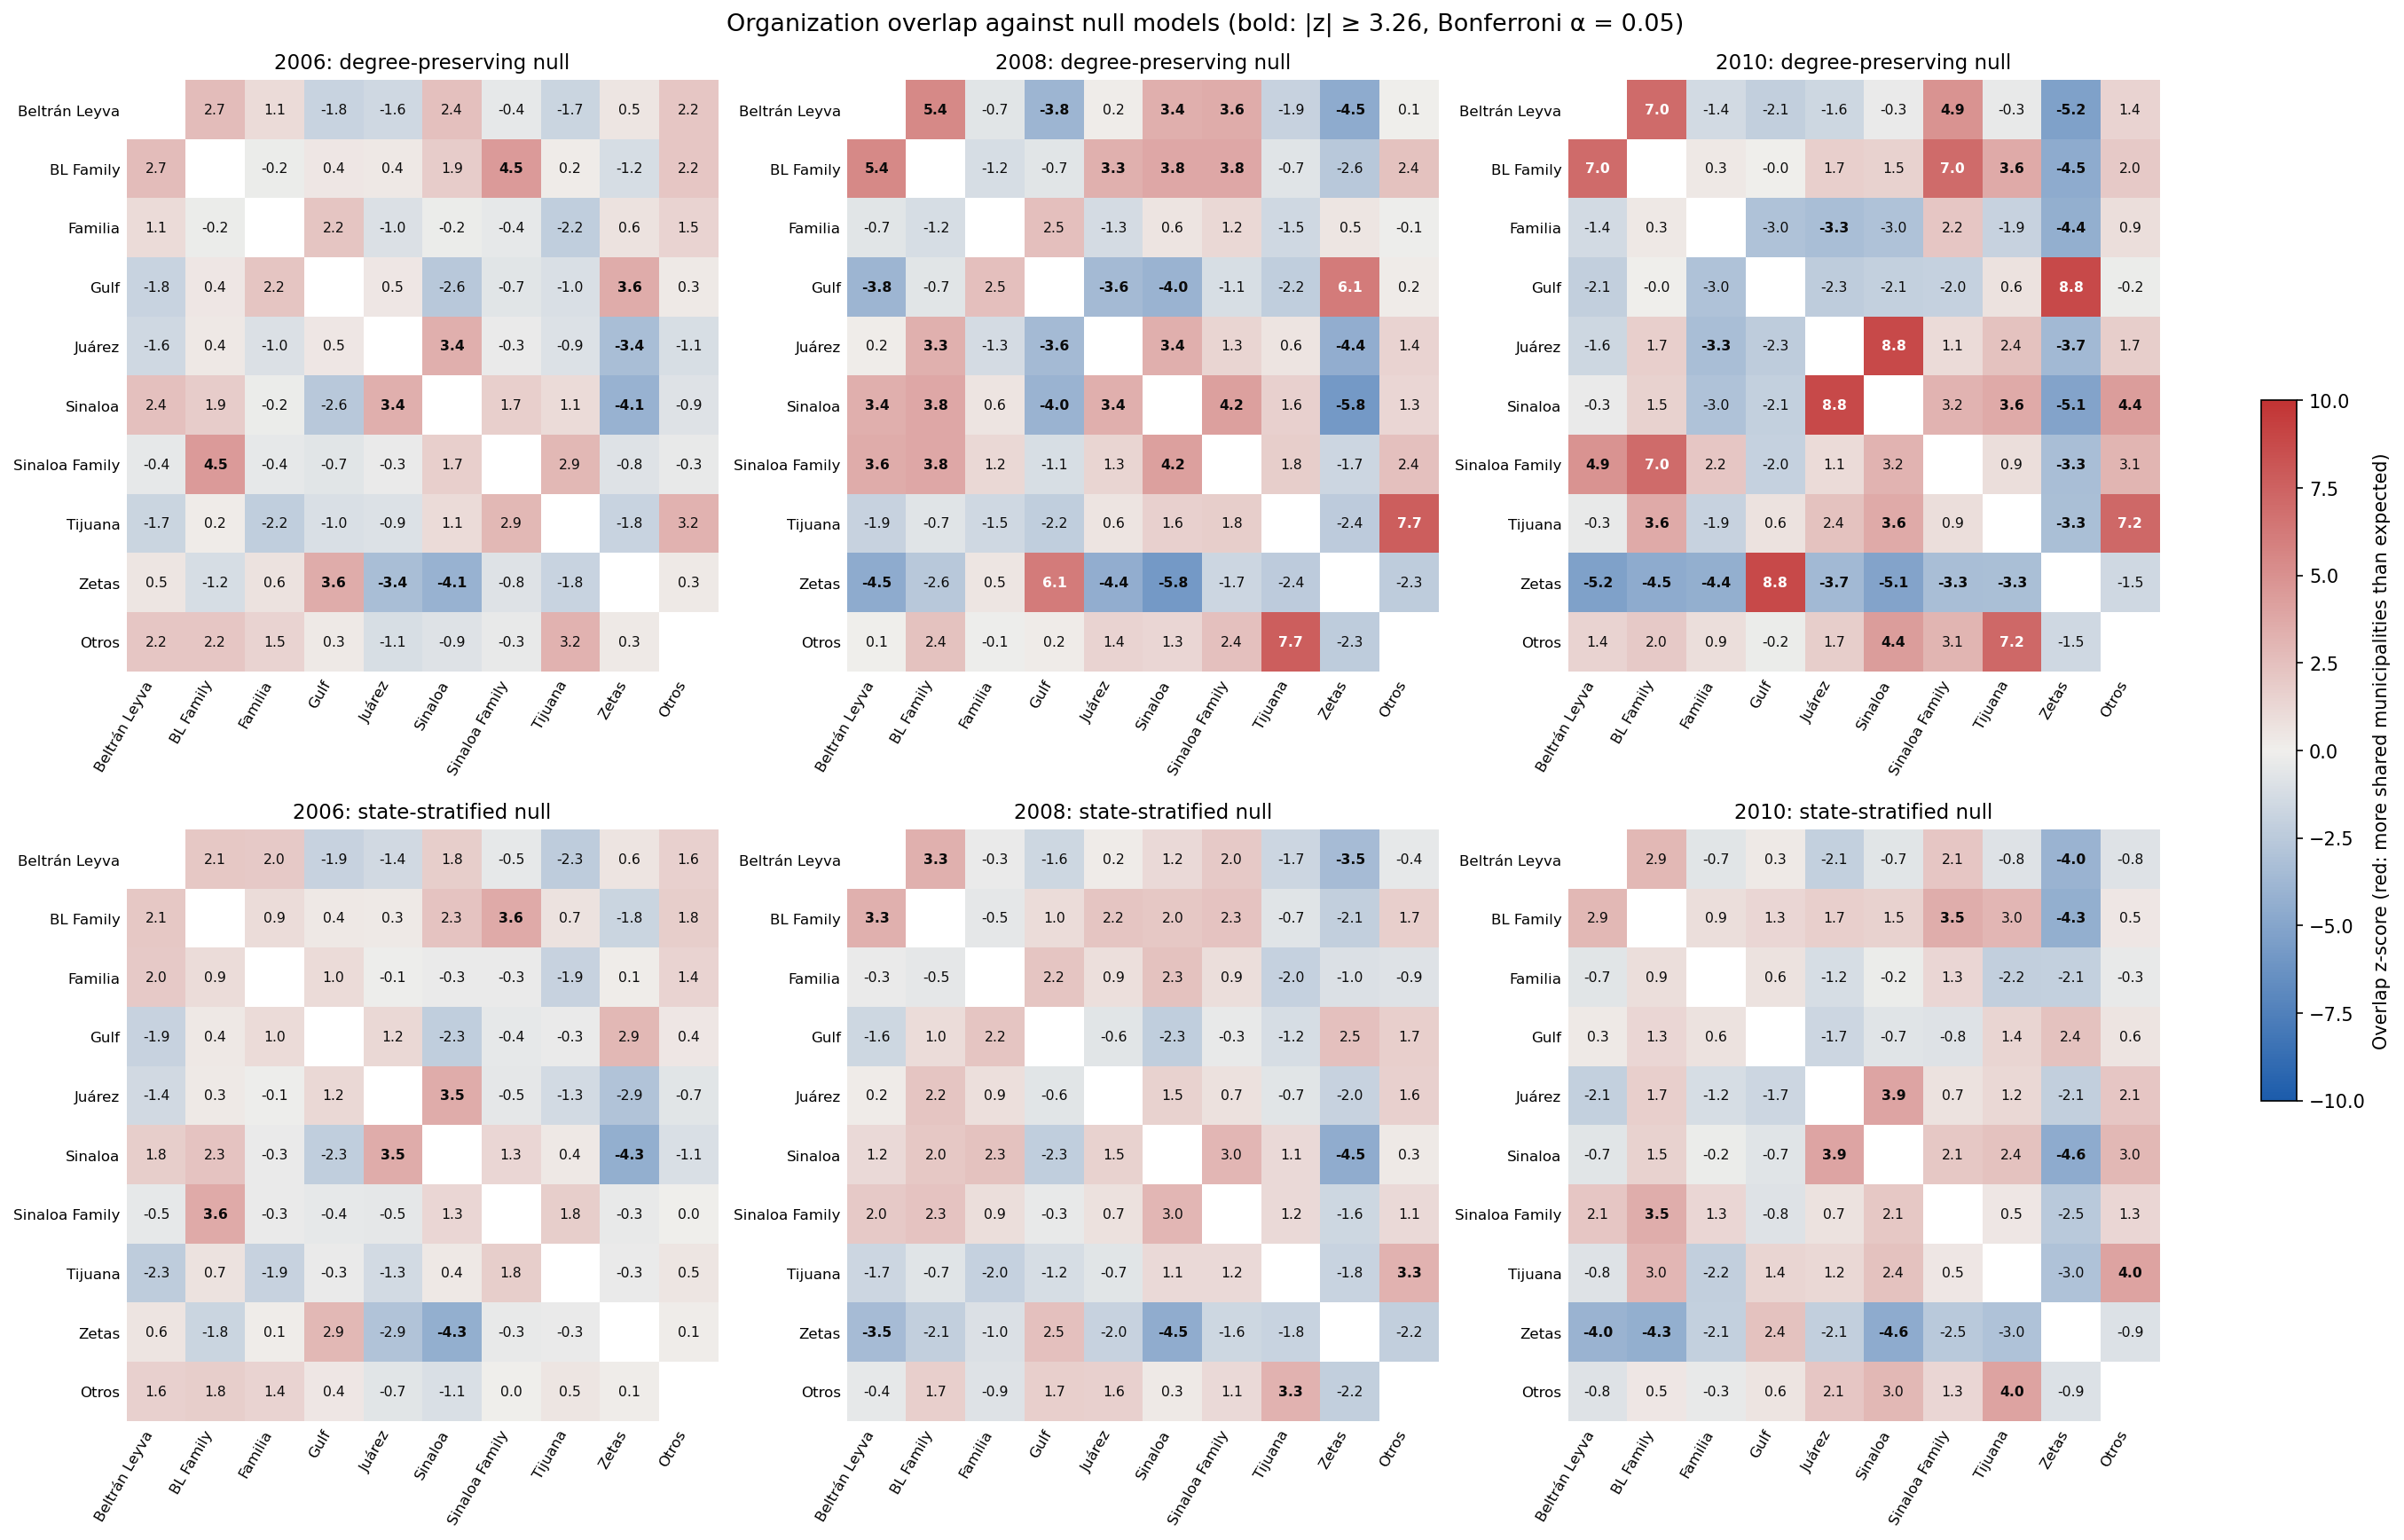

In [13]:
labels = [display_names[c] for c in organization_columns]
fig, axes = plt.subplots(2, len(focus_years), figsize=(18, 11.5), constrained_layout=True)
limit = 10
for col, year in enumerate(focus_years):
    for row, (null, title) in enumerate([("degree", "degree-preserving null"), ("state", "state-stratified null")]):
        ax = axes[row, col]
        z = overlap_z[(year, null)].to_numpy()
        masked = np.ma.masked_where(np.eye(len(z), dtype=bool), z)
        image = ax.imshow(masked, cmap=diverging_cmap, vmin=-limit, vmax=limit)
        for i in range(len(z)):
            for j in range(len(z)):
                if i != j:
                    ax.text(j, i, f"{z[i, j]:.1f}", ha="center", va="center", fontsize=7.5,
                            fontweight="bold" if abs(z[i, j]) >= critical_z else "normal",
                            color="white" if abs(z[i, j]) > 6 else "#0b0b0b")
        ax.set_xticks(range(len(labels)), labels, rotation=60, ha="right", fontsize=8)
        ax.set_yticks(range(len(labels)), labels, fontsize=8)
        ax.set_title(f"{year}: {title}", fontsize=11)
        ax.tick_params(length=0)
        for spine in ax.spines.values():
            spine.set_visible(False)
fig.colorbar(image, ax=axes, shrink=0.5, label="Overlap z-score (red: more shared municipalities than expected)")
fig.suptitle(f"Organization overlap against null models (bold: |z| ≥ {critical_z:.2f}, Bonferroni α = 0.05)", fontsize=13)
show_presentation_figure(fig)

In [14]:
pair_rows = []
for year in focus_years:
    for a_index, a in enumerate(organization_columns):
        for b in organization_columns[a_index + 1:]:
            pair_rows.append({
                "year": year, "pair": f"{display_names[a]} – {display_names[b]}",
                "shared_municipalities": int(overlap_observed[year][organization_columns.index(a), organization_columns.index(b)]),
                "z_degree_null": overlap_z[(year, "degree")].loc[a, b],
                "z_state_null": overlap_z[(year, "state")].loc[a, b],
            })
pair_table = pd.DataFrame(pair_rows)
pair_table["significant_after_state_control"] = pair_table["z_state_null"].abs() >= critical_z
pair_wide = pair_table.pivot(index="pair", columns="year", values="z_state_null")
significant_pairs = pair_wide[(pair_wide.abs() >= critical_z).any(axis=1)]
print("State-stratified z-scores for pairs significant in at least one focus year:")
display(significant_pairs.round(1).sort_values(focus_years[-1], ascending=False))

State-stratified z-scores for pairs significant in at least one focus year:


year,2006,2008,2010
pair,,,
Tijuana – Otros,0.5,3.3,4.0
Juárez – Sinaloa,3.5,1.5,3.9
BL Family – Sinaloa Family,3.6,2.3,3.5
Beltrán Leyva – BL Family,2.1,3.3,2.9
Beltrán Leyva – Zetas,0.6,-3.5,-4.0
BL Family – Zetas,-1.8,-2.1,-4.3
Sinaloa – Zetas,-4.3,-4.5,-4.6


## Organization backbone

The backbone keeps only organization pairs whose overlap remains significant under the **state-stratified** null. Solid red edges mean significantly more shared municipalities than expected given degrees and states; dashed blue edges mean significantly fewer. Edge width grows with |z|. Node size is the number of associated active municipalities. Positions are fixed across years so that changes are visible.

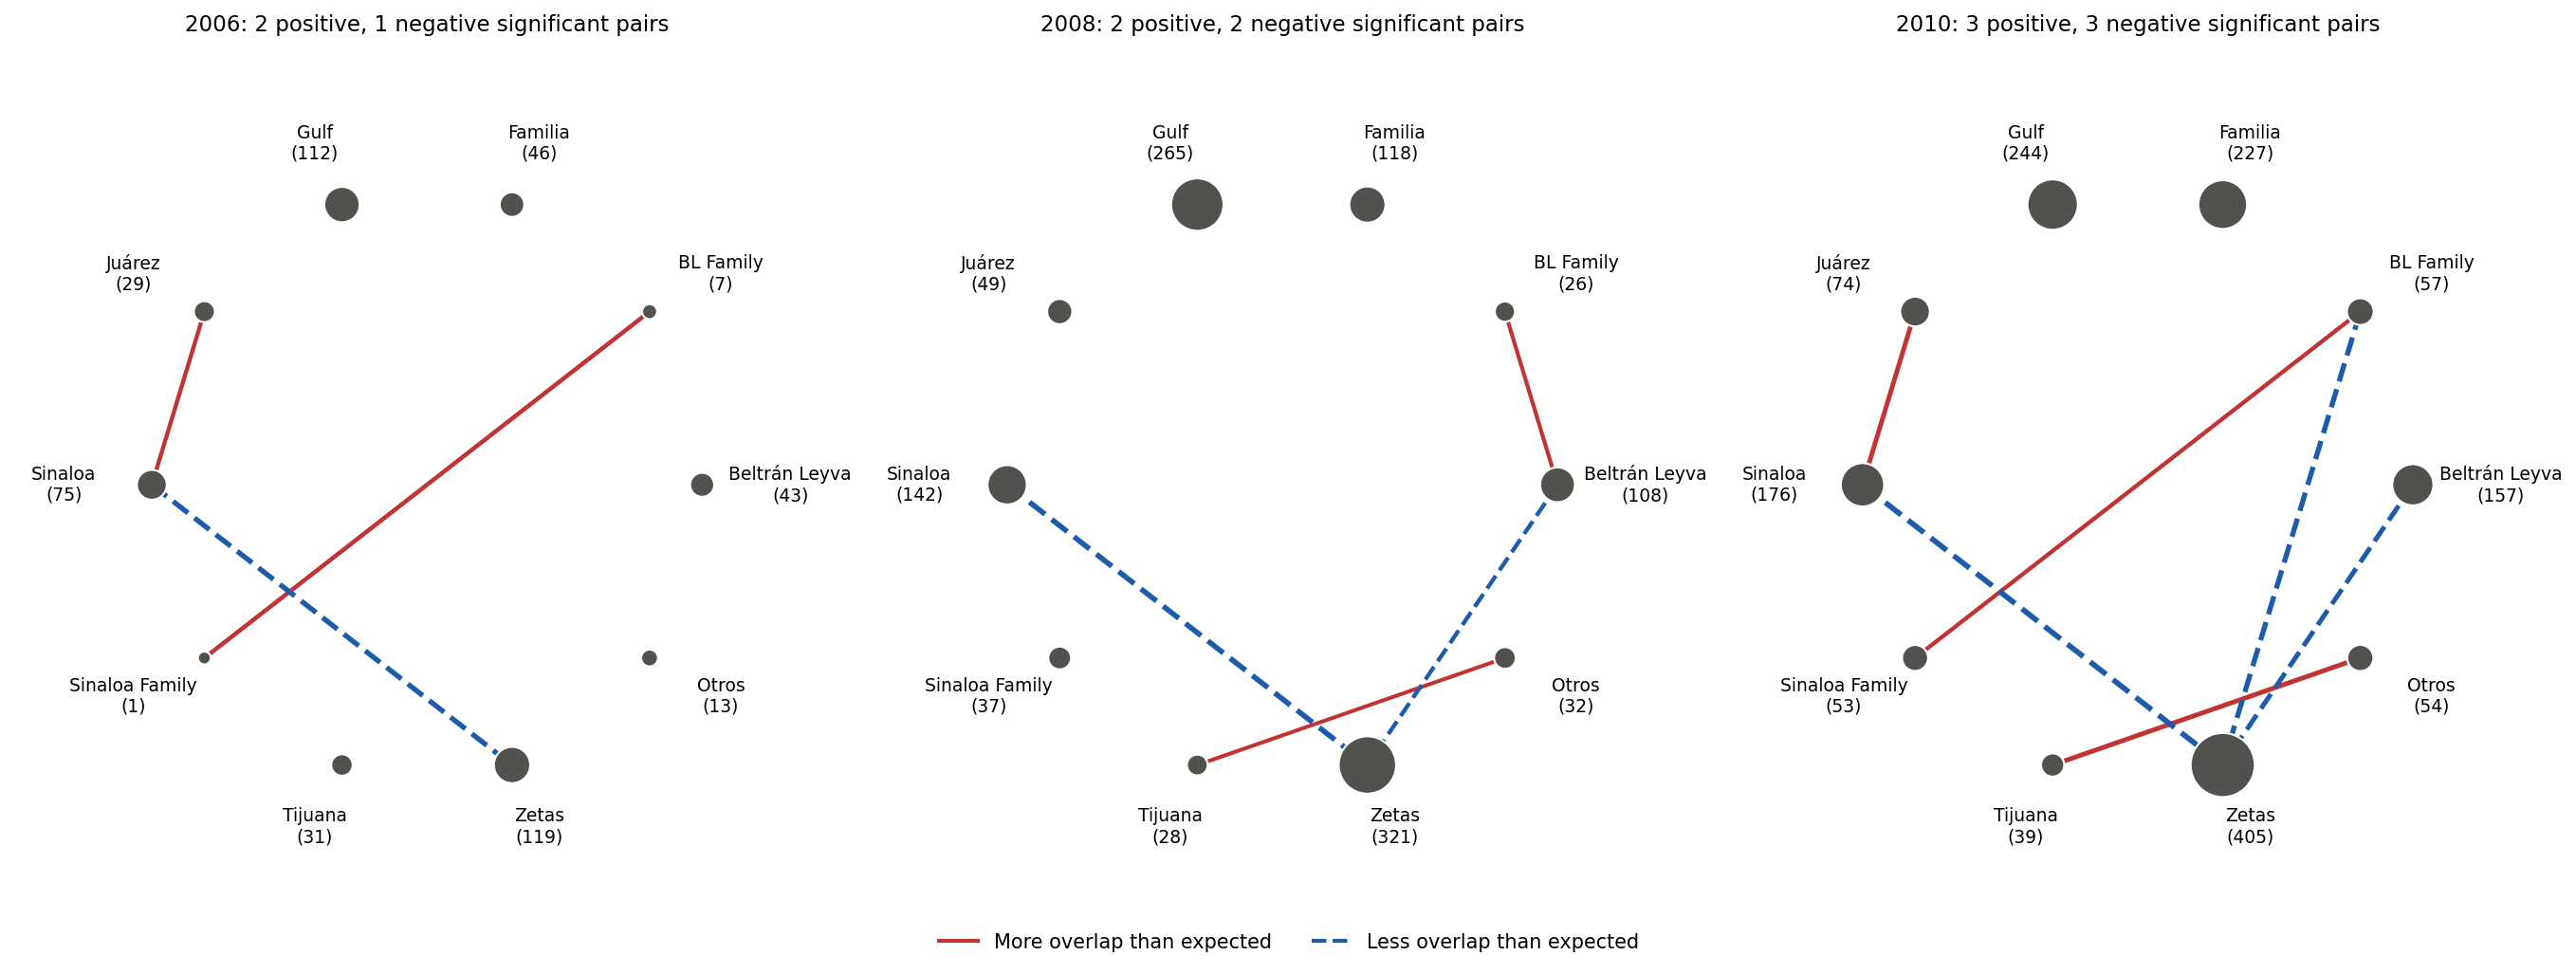

In [15]:
fig, axes = plt.subplots(1, len(focus_years), figsize=(18, 6.5), constrained_layout=True)
backbone_positions = nx.circular_layout(organization_columns)
organization_backbones = {}
for ax, year in zip(axes, focus_years):
    z = overlap_z[(year, "state")]
    degrees = active_by_year[year][organization_columns].sum()
    backbone = nx.Graph()
    backbone.add_nodes_from(organization_columns)
    for a_index, a in enumerate(organization_columns):
        for b in organization_columns[a_index + 1:]:
            if abs(z.loc[a, b]) >= critical_z:
                backbone.add_edge(a, b, z=z.loc[a, b])
    organization_backbones[year] = backbone
    positive = [(a, b) for a, b, w in backbone.edges(data="z") if w > 0]
    negative = [(a, b) for a, b, w in backbone.edges(data="z") if w < 0]
    nx.draw_networkx_edges(backbone, backbone_positions, edgelist=positive, ax=ax, edge_color="#c23434",
                           width=[0.6 * abs(backbone.edges[e]["z"]) for e in positive])
    nx.draw_networkx_edges(backbone, backbone_positions, edgelist=negative, ax=ax, edge_color="#1c5cab",
                           style="dashed", width=[0.6 * abs(backbone.edges[e]["z"]) for e in negative])
    nx.draw_networkx_nodes(backbone, backbone_positions, ax=ax, node_color="#52514e", edgecolors="white",
                           node_size=[40 + 2.5 * degrees[n] for n in organization_columns])
    for node, (x, y) in backbone_positions.items():
        ax.text(x * 1.32, y * 1.22,f"{display_names[node]}\n({degrees[node]})", ha="center", va="center", fontsize=9)
    ax.set_title(f"{year}: {len(positive)} positive, {len(negative)} negative significant pairs", fontsize=11)
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    ax.axis("off")
fig.legend(handles=[Line2D([], [], color="#c23434", lw=2, label="More overlap than expected"),
                    Line2D([], [], color="#1c5cab", lw=2, ls="--", label="Less overlap than expected")],
           loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.04))
show_presentation_figure(fig)

### Yearly rivalry scores used as predictors

State-stratified z-scores are computed for every year from 1990 to 2009. Features for an outcome in year *t+1* use only the z-scores and associations of year *t*, so no information from the outcome year leaks into the predictors. For predictors, an organization pair counts as **avoiding** when z ≤ −1.96 and **overlapping** when z ≥ 1.96. This is a fixed feature definition, not a significance test, so no multiple-comparison correction is applied.

In [16]:
feature_z = norm.isf(0.025)
rival_z = {}
for year in range(min(years), max(years)):
    if year in focus_years:
        rival_z[year] = overlap_z[(year, "state")]
    else:
        rival_z[year], _ = overlap_zscores(active_records(year), True, seed=1000 + year)

avoiding_pairs = pd.DataFrame([
    {"year": year,
     "avoiding_pairs": int((np.triu(z.to_numpy(), 1) <= -feature_z).sum()),
     "overlapping_pairs": int((np.triu(z.to_numpy(), 1) >= feature_z).sum())}
    for year, z in rival_z.items()
]).set_index("year")
display(avoiding_pairs.T)

year,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009
avoiding_pairs,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,3,4,4,6,6
overlapping_pairs,0,0,0,0,0,0,1,0,1,1,1,2,0,1,1,3,6,8,10,9


## H1: expansion within states

For adjacent years *t* → *t+1* (2001→2002 through 2009→2010), each candidate pair is a municipality–organization pair **absent** at *t*, for an organization active somewhere at *t*. Candidates are split by whether that organization was already associated with **another municipality in the same state** at *t*. The outcome is a new association at *t+1*.

The rate ratio compares the two groups. The 95% interval resamples states with replacement (1,000 bootstrap samples), because candidates in the same state are not independent. The `Otros` aggregate category is excluded in a sensitivity check. The data contain no municipality adjacency, so the state is a coarse stand-in for geographic proximity.

In [17]:
def expansion_candidates(exclude=()):
    frames = []
    for year in range(2001, 2010):
        before = data[data["Year"] == year].set_index("Code")
        after = data[data["Year"] == year + 1].set_index("Code")
        shared = before.index.intersection(after.index)
        before, after = before.loc[shared], after.loc[shared]
        for organization in organization_columns:
            if organization in exclude or before[organization].sum() == 0:
                continue
            present_states = set(before.loc[before[organization] == 1, "State"])
            candidates = before[organization] == 0
            frames.append(pd.DataFrame({
                "year": year + 1, "organization": organization,
                "state": before.loc[candidates, "State"].to_numpy(),
                "in_present_state": before.loc[candidates, "State"].isin(present_states).to_numpy(),
                "new": (after.loc[candidates, organization] == 1).to_numpy(),
            }))
    return pd.concat(frames, ignore_index=True)

def rate_ratio(candidates):
    rates = candidates.groupby("in_present_state")["new"].mean()
    return rates.get(True, np.nan) / rates.get(False, np.nan)

def state_bootstrap_interval(candidates, samples=1000, seed=0):
    rng = np.random.default_rng(seed)
    by_state = {state: group for state, group in candidates.groupby("state")}
    states = list(by_state)
    ratios = [rate_ratio(pd.concat([by_state[s] for s in rng.choice(states, len(states))])) for _ in range(samples)]
    return np.nanpercentile(ratios, [2.5, 97.5])

expansion_rows = []
for label, exclude in [("all categories", ()), ("excluding Otros", ("Otros",))]:
    candidates = expansion_candidates(exclude)
    low, high = state_bootstrap_interval(candidates)
    grouped = candidates.groupby("in_present_state")["new"]
    expansion_rows.append({
        "analysis": label, "candidates": len(candidates), "new_associations": int(candidates["new"].sum()),
        "rate_same_state": grouped.mean()[True], "rate_other_states": grouped.mean()[False],
        "rate_ratio": rate_ratio(candidates), "ratio_ci_low": low, "ratio_ci_high": high,
        "share_of_new_in_present_state": candidates.loc[candidates["new"], "in_present_state"].mean(),
    })
    if label == "all categories":
        expansion_main = candidates
expansion_summary = pd.DataFrame(expansion_rows).set_index("analysis")
display(expansion_summary.round(4))

expansion_by_year = expansion_main.groupby(["year", "in_present_state"])["new"].mean().unstack()
expansion_by_year.columns = ["other states", "same state"]
expansion_by_year["rate ratio"] = expansion_by_year["same state"] / expansion_by_year["other states"]
display(expansion_by_year.round(4))

,candidates,new_associations,rate_same_state,rate_other_states,rate_ratio,ratio_ci_low,ratio_ci_high,share_of_new_in_present_state
analysis,,,,,,,,
all categories,187211,3271,0.0326,0.0062,5.2219,3.4450,7.6037,0.7946
excluding Otros,170130,3164,0.0341,0.0065,5.2680,3.4589,7.7533,0.8044


,other states,same state,rate ratio
year,,,
2002,0.0019,0.0046,2.4951
2003,0.0042,0.0119,2.8635
2004,0.0044,0.0161,3.6854
2005,0.0099,0.0284,2.8697
2006,0.0061,0.0291,4.8018
2007,0.0054,0.0367,6.7825
2008,0.0129,0.0449,3.4912
2009,0.0073,0.0404,5.5699
2010,0.0061,0.0303,4.9525


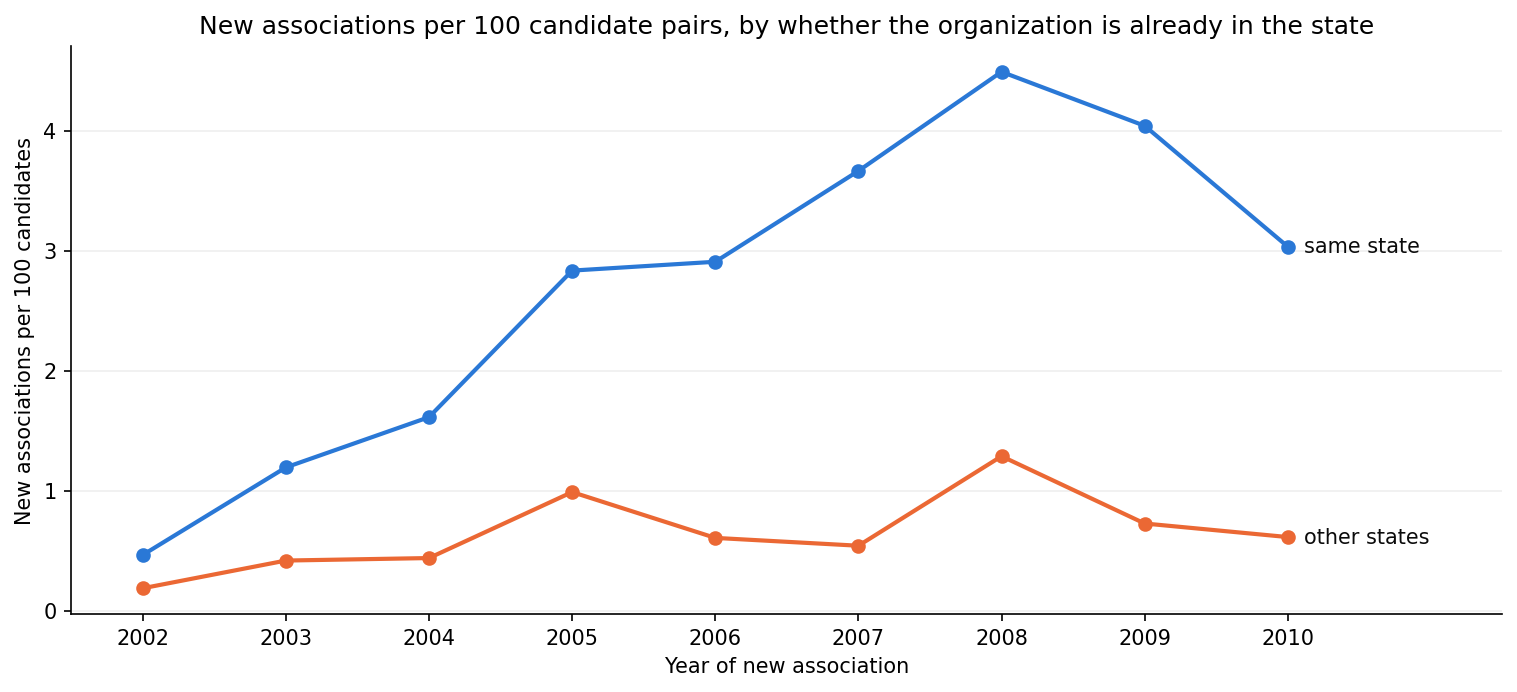

In [18]:
fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
for column, color in [("same state", "#2a78d6"), ("other states", "#eb6834")]:
    ax.plot(expansion_by_year.index, 100 * expansion_by_year[column], color=color, lw=2, marker="o", ms=6)
    last = expansion_by_year.index[-1]
    ax.annotate(column, (last, 100 * expansion_by_year.loc[last, column]), xytext=(8, 0),
                textcoords="offset points", va="center", color="#0b0b0b")
ax.set(title="New associations per 100 candidate pairs, by whether the organization is already in the state",
       xlabel="Year of new association", ylabel="New associations per 100 candidates")
ax.set_xticks(expansion_by_year.index)
ax.set_xlim(expansion_by_year.index[0] - 0.5, expansion_by_year.index[-1] + 1.5)
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
show_presentation_figure(fig)

## H2: formation of new associations

The measured outcome is a newly recorded association, not confirmed criminal expansion. Main analysis: pairs absent at year t, predicting presence at t+1, including reappearances. Sensitivity analyses restrict to first observed associations and exclude `Otros`.

Only municipalities recorded in both adjacent years are evaluated. Organizations become eligible after their first observed association anywhere in the historical data; we do not claim to predict the emergence of previously unobserved organizations. Excluded positives are counted. The dataset's category definitions are retrospective, which limits a strictly prospective interpretation.

Development evaluation predicts 2007–2008; final evaluation predicts 2009–2010. Models and features are fixed before examining final results. Each fold trains only on outcomes from earlier years, starting in 2000. No random row split or final-year tuning is used. Historical inactivity is not proof of true absence.

In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from statsmodels.genmod.generalized_linear_model import GLM
from statsmodels.genmod.families import Binomial

# Fixed node indexing makes annual matrices and historical records comparable.
municipality_codes = sorted(data["Code"].unique())
code_index = {value: i for i, value in enumerate(municipality_codes)}
org_index = {value: i for i, value in enumerate(organization_columns)}
matrices, recorded_codes = {}, {}
for year, rows in data.groupby("Year"):
    matrix = np.zeros((len(municipality_codes), len(organization_columns)), dtype=np.int32)
    indexes = rows["Code"].map(code_index).to_numpy()
    matrix[indexes] = rows[organization_columns].to_numpy(dtype=np.int32)
    matrices[int(year)] = matrix
    recorded_codes[int(year)] = set(rows["Code"])
state_by_code = data.drop_duplicates("Code").set_index("Code")["State"].to_dict()

last_seen = np.full_like(matrices[min(years)], -1)
previous_matrix = np.zeros_like(last_seen)
research_frames, eligibility_records = [], []
for year in years[:-1]:
    current, following = matrices[year], matrices[year + 1]
    last_seen[current == 1] = year
    eligible_orgs = (last_seen >= 0).any(axis=0)
    shared_indexes = np.array([code_index[c] for c in sorted(recorded_codes[year] & recorded_codes[year + 1])])
    candidate_mask = (current[shared_indexes] == 0) & eligible_orgs[None, :]
    local_m, org = np.where(candidate_mask)
    municipality = shared_indexes[local_m]
    # Count length-three walks. For an absent pair, these are length-three paths.
    three_paths = current @ (current.T @ current)
    municipality_degree, organization_degree = current.sum(axis=1), current.sum(axis=0)
    prior_m_degree, prior_o_degree = previous_matrix.sum(axis=1), previous_matrix.sum(axis=0)
    had_previous = last_seen[municipality, org] >= 0
    frame = pd.DataFrame({
        "prediction_year": year + 1,
        "municipality": [municipality_codes[i] for i in municipality],
        "organization": [organization_columns[i] for i in org],
        "new_link": following[municipality, org],
        "previous_association": had_previous.astype(int),
        "years_since_previous": np.where(had_previous, year - last_seen[municipality, org], 0),
        "municipality_degree": municipality_degree[municipality],
        "organization_degree": organization_degree[org],
        "three_step_paths": three_paths[municipality, org],
        "municipality_degree_change": municipality_degree[municipality] - prior_m_degree[municipality],
        "organization_degree_change": organization_degree[org] - prior_o_degree[org],
    })
    frame["state"] = frame["municipality"].map(state_by_code)
    for feature in ["municipality_degree", "organization_degree", "three_step_paths"]:
        frame[f"log_{feature}"] = np.log1p(frame[feature])
    research_frames.append(frame)
    eligibility_records.append({"prediction_year": year + 1, "eligible_pairs": len(frame),
        "new_links": int(frame["new_link"].sum()),
        "positives_excluded_unobserved_organization": int(((current[shared_indexes] == 0) & (following[shared_indexes] == 1) & ~eligible_orgs[None, :]).sum())})
    previous_matrix = current
research_data = pd.concat(research_frames, ignore_index=True)
eligibility_summary = pd.DataFrame(eligibility_records).set_index("prediction_year")
display(eligibility_summary)

# Every candidate is absent at t; all features use t or earlier.
assert (research_data["years_since_previous"] >= 0).all()
assert not research_data.duplicated(["prediction_year", "municipality", "organization"]).any()
assert (research_data["three_step_paths"] >= 0).all()
print(f"Candidate pair-year observations: {len(research_data):,}")

,eligible_pairs,new_links,positives_excluded_unobserved_organization
prediction_year,,,
1991,0,0,6
1992,4908,1,5
1993,9822,19,2
1994,12261,25,0
1995,12254,15,0
1996,12262,27,1
1997,14706,41,1
1998,17148,37,0
1999,17150,24,0


Candidate pair-year observations: 334,314


### Territorial features

For candidate municipality *m* and organization *c*, using year *t* only:

- `other_organizations`: other organizations associated with *m*.
- `avoider_present` / `overlapper_present`: at least one of those organizations has a yearly z-score with *c* at or below −1.96 / at or above 1.96.
- `mean_rival_z`: the average z-score between *c* and the organizations in *m* (0 when *m* has none), which keeps information below the cut-offs.
- `organization_in_state` and `log_organization_state_count`: whether, and in how many other municipalities, *c* is present in *m*'s state (H1).

For rate tables, each pair gets one `rival_context`; when both an avoiding and an overlapping organization are present, "avoiding rival present" takes precedence. The same function builds these features for the disappearance analysis.

In [20]:
territory_features = ["mean_rival_z", "avoider_present", "overlapper_present",
                      "organization_in_state", "log_organization_state_count"]

def add_territory_features(frame):
    """Add territorial features from year prediction_year - 1 to municipality–organization pairs."""
    parts = []
    for feature_year, part in frame.groupby(frame["prediction_year"] - 1):
        current = matrices[feature_year]
        z = rival_z[feature_year].to_numpy()
        m = part["municipality"].map(code_index).to_numpy()
        c = part["organization"].map(org_index).to_numpy()
        others = current[m].astype(float)
        others[np.arange(len(m)), c] = 0
        z_with_focal = z[:, c].T
        n_others = others.sum(axis=1)
        state_counts = data[data["Year"] == feature_year].groupby("State")[organization_columns].sum()
        in_state = state_counts.reindex(part["state"]).to_numpy()[np.arange(len(m)), c] - current[m, c]
        part = part.copy()
        part["other_organizations"] = n_others
        part["mean_rival_z"] = np.where(n_others > 0, (others * z_with_focal).sum(axis=1) / np.maximum(n_others, 1), 0.0)
        part["avoider_present"] = ((others * (z_with_focal <= -feature_z)).sum(axis=1) > 0).astype(int)
        part["overlapper_present"] = ((others * (z_with_focal >= feature_z)).sum(axis=1) > 0).astype(int)
        part["organization_in_state"] = (in_state > 0).astype(int)
        part["log_organization_state_count"] = np.log1p(in_state)
        parts.append(part)
    return pd.concat(parts).sort_index()

def rival_context(frame):
    return pd.Categorical(np.select(
        [frame["other_organizations"] == 0, frame["avoider_present"] == 1, frame["overlapper_present"] == 1],
        ["no other organization", "avoiding rival present", "overlapping organization present"],
        "only neutral organizations"),
        categories=["no other organization", "only neutral organizations",
                    "overlapping organization present", "avoiding rival present"])

research_data = add_territory_features(research_data)
research_data["rival_context"] = rival_context(research_data)
assert not research_data[territory_features].isna().any().any()
display(research_data.groupby("rival_context", observed=True)["new_link"].agg(["size", "sum", "mean"]))

,size,sum,mean
rival_context,,,
no other organization,313265,1608,0.005133
only neutral organizations,12493,862,0.068999
overlapping organization present,3037,482,0.158709
avoiding rival present,5519,626,0.113426


## Temporal prediction and baselines

Average precision (AP) evaluates rankings under class imbalance. The constant-score baseline has AP equal to the observed link-formation rate. Precision@100 and recall@100 summarize the first 100 ranked candidates, breaking ties by municipality and organization identifier.

Compare municipality degree, degree product, a history/organization model, and that same model plus structural features. Logistic models use ordinary unweighted likelihood with fixed regularization (`C=1`); preprocessing is fit separately on each training fold. Sensitivity comparisons use the same filtered candidate population for every model. First observed means not previously observed in this file, not necessarily genuinely new.

State-block bootstrap intervals quantify variation across geographical groups in the final-year test sample, conditional on trained models. They do not capture all temporal/network dependence or uncertainty from retraining.

For the constant baseline, precision@100 and recall@100 are the expected values under random selection rather than values from arbitrary identifier-based ties. Final evaluation uses rolling retraining: 2009 outcomes become available when predicting 2010. No model settings change between folds.

A further model, **History + territory**, adds the territorial features defined above (organization presence in the state, rival context and mean rivalry z-score). Its AP gain over the history model is evaluated with the same paired state-block bootstrap.

In [21]:
history_features = ["previous_association", "years_since_previous"]
network_features = ["log_municipality_degree", "log_organization_degree", "log_three_step_paths",
                    "municipality_degree_change", "organization_degree_change"]

def make_link_model(numeric_features):
    preprocessing = ColumnTransformer([
        ("numeric", StandardScaler(), numeric_features),
        ("organization", OneHotEncoder(handle_unknown="ignore"), ["organization"]),
    ])
    return make_pipeline(preprocessing, LogisticRegression(C=1, max_iter=1000, solver="lbfgs"))

def ranking_metrics(labels, scores, k=100):
    labels, scores = np.asarray(labels), np.asarray(scores)
    selected = np.argsort(-scores, kind="stable")[:min(k, len(labels))]
    positives = int(labels.sum())
    return {"average_precision": average_precision_score(labels, scores) if positives else np.nan,
        "precision_at_100": labels[selected].mean() if len(selected) else np.nan,
        "recall_at_100": labels[selected].sum() / positives if positives else np.nan}

scenario_filters = {
    "Main": lambda frame: frame,
    "First observed only": lambda frame: frame[frame["previous_association"] == 0],
    "Exclude Otros": lambda frame: frame[frame["organization"] != "Otros"],
}
evaluation_records, heldout_predictions = [], []
for scenario, filter_frame in scenario_filters.items():
    scenario_data = filter_frame(research_data)
    for target_year in [2007, 2008, 2009, 2010]:
        train = scenario_data[(scenario_data["prediction_year"] >= 2000) & (scenario_data["prediction_year"] < target_year)]
        test = scenario_data[scenario_data["prediction_year"] == target_year].sort_values(["municipality", "organization"]).copy()
        assert train["prediction_year"].max() < test["prediction_year"].min()
        assert train["new_link"].nunique() == 2 and len(test) > 0
        scores = {
            "Constant baseline": np.zeros(len(test)),
            "Municipality degree": test["municipality_degree"].to_numpy(),
            "Degree product": (test["municipality_degree"] * test["organization_degree"]).to_numpy(),
        }
        for label, features in [("History model", history_features),
                                ("History + structure", history_features + network_features),
                                ("History + territory", history_features + territory_features)]:
            fitted = make_link_model(features).fit(train, train["new_link"])
            scores[label] = fitted.predict_proba(test)[:, 1]
        for label, predictions in scores.items():
            metrics = ranking_metrics(test["new_link"], predictions)
            if label == "Constant baseline":
                metrics["precision_at_100"] = test["new_link"].mean()
                metrics["recall_at_100"] = min(100, len(test)) / len(test)
            evaluation_records.append({"scenario": scenario, "year": target_year,
                "split": "Development" if target_year < 2009 else "Final",
                "model": label, "candidates": len(test), "positives": int(test["new_link"].sum()),
                "formation_rate": test["new_link"].mean(), **metrics})
        if scenario == "Main" and target_year >= 2009:
            for label, predictions in scores.items(): test[label] = predictions
            heldout_predictions.append(test)
evaluation_results = pd.DataFrame(evaluation_records)
final_predictions = pd.concat(heldout_predictions, ignore_index=True)
display(evaluation_results)

# Paired state-block bootstrap: identical weights for each model in each replicate.
rng = np.random.default_rng(42)
bootstrap_records = []
for target_year, test in final_predictions.groupby("prediction_year"):
    states = sorted(test["state"].unique())
    state_codes = pd.Categorical(test["state"], categories=states).codes
    differences = {"History + structure": [], "History + territory": []}
    for repetition in range(200):
        multiplicity = np.bincount(rng.integers(0, len(states), len(states)), minlength=len(states))
        weights = multiplicity[state_codes]
        if np.dot(weights, test["new_link"]) == 0: continue
        history_ap = average_precision_score(test["new_link"], test["History model"], sample_weight=weights)
        for label in differences:
            differences[label].append(average_precision_score(test["new_link"], test[label], sample_weight=weights) - history_ap)
    for label, values in differences.items():
        point = average_precision_score(test["new_link"], test[label]) - average_precision_score(test["new_link"], test["History model"])
        low, high = np.quantile(values, [0.025, 0.975])
        bootstrap_records.append({"year": target_year, "model": label, "AP_gain_over_history": point,
            "state_bootstrap_95_lower": low, "state_bootstrap_95_upper": high, "state_blocks": len(states)})
prediction_uncertainty = pd.DataFrame(bootstrap_records).set_index(["year", "model"])
display(prediction_uncertainty)

,scenario,year,split,model,candidates,positives,formation_rate,average_precision,precision_at_100,recall_at_100
0,Main,2007,Development,Constant baseline,24094,467,0.019382,0.019382,0.019382,0.004150
1,Main,2007,Development,Municipality degree,24094,467,0.019382,0.066979,0.200000,0.042827
2,Main,2007,Development,Degree product,24094,467,0.019382,0.133338,0.290000,0.062099
3,Main,2007,Development,History model,24094,467,0.019382,0.170032,0.420000,0.089936
4,Main,2007,Development,History + structure,24094,467,0.019382,0.211974,0.380000,0.081370
...,...,...,...,...,...,...,...,...,...,...
67,Exclude Otros,2010,Final,Municipality degree,20778,487,0.023438,0.095599,0.230000,0.047228
68,Exclude Otros,2010,Final,Degree product,20778,487,0.023438,0.132139,0.170000,0.034908
69,Exclude Otros,2010,Final,History model,20778,487,0.023438,0.255893,0.470000,0.096509
70,Exclude Otros,2010,Final,History + structure,20778,487,0.023438,0.244806,0.290000,0.059548


AP_gain_over_history  state_bootstrap_95_lower  \
year model                                                                 
2009 History + structure              0.030755                 -0.008204   
     History + territory              0.084238                  0.051169   
2010 History + structure             -0.008094                 -0.064020   
     History + territory              0.038466                  0.001252   

                          state_bootstrap_95_upper  state_blocks  
year model                                                        
2009 History + structure                  0.064644            32  
     History + territory                  0.117726            32  
2010 History + structure                  0.031420            32  
     History + territory                  0.070189            32

## Statistical associations on development data

For interpretation, fit a separate unpenalized binomial GLM to prediction years 2000–2008. Organization and year indicators account for differences across categories and years. Numerical features are standardized, so their odds ratios correspond to a one-standard-deviation increase; the previous-association odds ratio compares previously observed versus never observed pairs.

Confidence intervals use state-clustered covariance (32 states at most), allowing dependence within each state. Cross-state network dependence, few clusters, reporting bias and omitted variables still limit inference. These are conditional associations, not causal effects. The inferential model is distinct from the regularized prediction models. Report intervals and effect sizes rather than selecting features by p-values.

In [22]:
inference_data = research_data[research_data["prediction_year"].between(2000, 2008)].copy()
standardized_names = {}
for feature in ["years_since_previous"] + network_features:
    deviation = inference_data[feature].std(ddof=0)
    if deviation == 0: continue
    name = f"z_{feature}"
    inference_data[name] = (inference_data[feature] - inference_data[feature].mean()) / deviation
    standardized_names[name] = feature
inference_terms = ["previous_association"] + list(standardized_names)
formula = "new_link ~ " + " + ".join(inference_terms) + " + C(organization) + C(prediction_year)"
association_model = GLM.from_formula(formula, data=inference_data, family=Binomial()).fit(
    cov_type="cluster", cov_kwds={"groups": inference_data["state"]}, maxiter=100)
assert association_model.converged, "Inferential GLM did not converge."
intervals = association_model.conf_int()
effect_results = pd.DataFrame({
    "feature": [standardized_names.get(term, term) for term in inference_terms],
    "odds_ratio": np.exp(association_model.params[inference_terms].to_numpy()),
    "95_lower": np.exp(intervals.loc[inference_terms, 0].to_numpy()),
    "95_upper": np.exp(intervals.loc[inference_terms, 1].to_numpy()),
})
display(effect_results)
print(f"Development observations: {len(inference_data):,}")
print(f"Development positive outcomes: {inference_data['new_link'].sum():,}")
print(f"State clusters: {inference_data['state'].nunique()}")

# Descriptive rates: candidate pairs, not a count of municipalities.
inference_data["municipality_degree_group"] = pd.cut(
    inference_data["municipality_degree"], bins=[-1, 0, 1, 2, np.inf], labels=["0", "1", "2", "3+"])
formation_rates = inference_data.groupby("municipality_degree_group", observed=True)["new_link"].agg(
    candidate_pairs="size", appearing_links="sum", formation_rate="mean")
display(formation_rates)

,feature,odds_ratio,95_lower,95_upper
0,previous_association,6.269128,4.683507,8.391567
1,years_since_previous,1.006659,0.978543,1.035583
2,log_municipality_degree,1.758940,1.607658,1.924457
3,log_organization_degree,2.141879,1.589583,2.886070
4,log_three_step_paths,0.964856,0.903683,1.030170
5,municipality_degree_change,0.856940,0.827514,0.887412
6,organization_degree_change,0.931215,0.826226,1.049545


Development observations: 187,168
Development positive outcomes: 2,238
State clusters: 32


,candidate_pairs,appearing_links,formation_rate
municipality_degree_group,,,
0,177038,1174,0.006631
1,6332,592,0.093493
2,2861,324,0.113247
3+,937,148,0.157951


### Formation by rival context

Rates use all prediction years 2000–2010; 95% intervals resample states (1,000 samples). The GLM uses the development window 2000–2008, like the model above, with organization and year fixed effects and state-clustered errors. Binary terms compare presence with absence; numerical controls are standardized.

In [23]:
def grouped_rates(frame, outcome, group, samples=1000, seed=0):
    counts = frame.groupby(["state", group], observed=False)[outcome].agg(["sum", "size"]).unstack(fill_value=0)
    events, totals = counts["sum"].to_numpy(float), counts["size"].to_numpy(float)
    rng = np.random.default_rng(seed)
    weights = rng.multinomial(len(events), np.full(len(events), 1 / len(events)), size=samples)
    bootstrap = (weights @ events) / np.maximum(weights @ totals, 1)
    return pd.DataFrame({
        "pairs": totals.sum(axis=0).astype(int), "events": events.sum(axis=0).astype(int),
        "rate": events.sum(axis=0) / np.maximum(totals.sum(axis=0), 1),
        "ci_low": np.percentile(bootstrap, 2.5, axis=0), "ci_high": np.percentile(bootstrap, 97.5, axis=0),
    }, index=counts["sum"].columns)

def fit_territory_glm(frame, outcome, binary_terms, numeric_controls):
    frame = frame.copy()
    names = {}
    for column in numeric_controls:
        deviation = frame[column].std(ddof=0)
        if deviation > 0:
            frame[f"z_{column}"] = (frame[column] - frame[column].mean()) / deviation
            names[f"z_{column}"] = column
    terms = binary_terms + list(names)
    formula = f"{outcome} ~ " + " + ".join(terms) + " + C(organization) + C(prediction_year)"
    model = GLM.from_formula(formula, data=frame, family=Binomial()).fit(
        cov_type="cluster", cov_kwds={"groups": frame["state"]}, maxiter=100)
    assert model.converged, f"{outcome} GLM did not converge."
    intervals = model.conf_int()
    return model, pd.DataFrame({
        "feature": [names.get(term, term) for term in terms],
        "odds_ratio": np.exp(model.params[terms].to_numpy()),
        "95_lower": np.exp(intervals.loc[terms, 0].to_numpy()),
        "95_upper": np.exp(intervals.loc[terms, 1].to_numpy()),
        "p_value": model.pvalues[terms].to_numpy(),
    })

formation_window = research_data[research_data["prediction_year"].between(2000, 2010)]
formation_by_context = grouped_rates(formation_window, "new_link", "rival_context")
formation_by_state_presence = grouped_rates(formation_window, "new_link", "organization_in_state")
print("Formation rate by rival context, 2000–2010")
display(formation_by_context)
print("Formation rate by organization presence in the state (H1)")
display(formation_by_state_presence)

formation_binary = ["previous_association", "organization_in_state", "avoider_present", "overlapper_present"]
formation_controls = ["years_since_previous", "log_municipality_degree", "log_organization_degree"]
formation_glm, formation_effects = fit_territory_glm(
    research_data[research_data["prediction_year"].between(2000, 2008)],
    "new_link", formation_binary, formation_controls)
print("Formation GLM, 2000–2008")
display(formation_effects)

Formation rate by rival context, 2000–2010


,pairs,events,rate,ci_low,ci_high
rival_context,,,,,
no other organization,213738,1464,0.006850,0.004003,0.011309
only neutral organizations,11533,817,0.070840,0.059086,0.083208
overlapping organization present,3013,482,0.159973,0.139334,0.184623
avoiding rival present,5519,626,0.113426,0.095483,0.133597


Formation rate by organization presence in the state (H1)


,pairs,events,rate,ci_low,ci_high
organization_in_state,,,,,
0,149476,765,0.005118,0.002866,0.009015
1,84327,2624,0.031117,0.021153,0.046535


Formation GLM, 2000–2008


,feature,odds_ratio,95_lower,95_upper,p_value
0,previous_association,10.114294,7.214186,14.180249,4.501525e-41
1,organization_in_state,1.964321,1.326367,2.909119,7.527072e-04
2,avoider_present,0.469937,0.330219,0.668770,2.731908e-05
3,overlapper_present,1.114922,0.815751,1.523810,4.949637e-01
4,years_since_previous,0.984728,0.959675,1.010435,2.418033e-01
5,log_municipality_degree,1.585693,1.448582,1.735781,1.661923e-23
6,log_organization_degree,1.646443,1.298934,2.086922,3.752101e-05


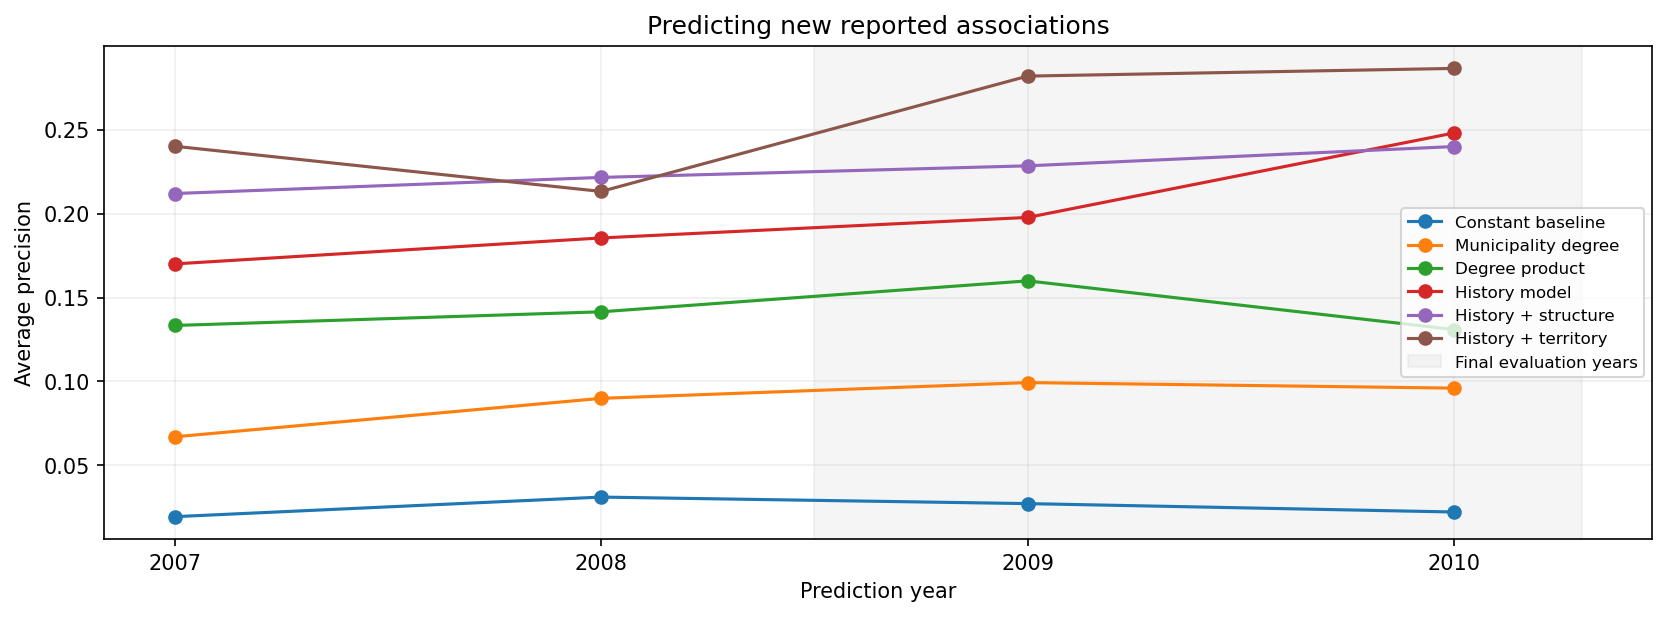

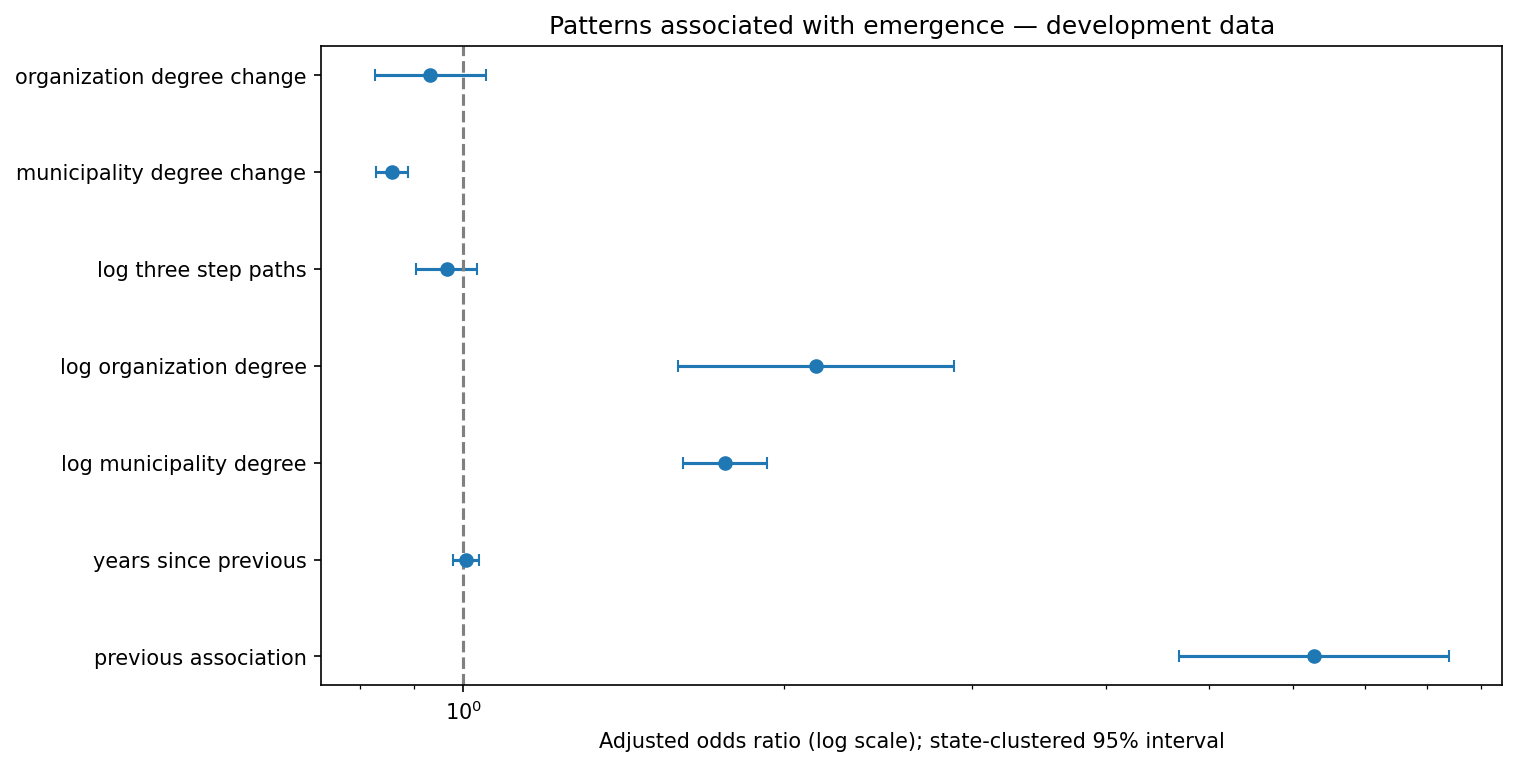

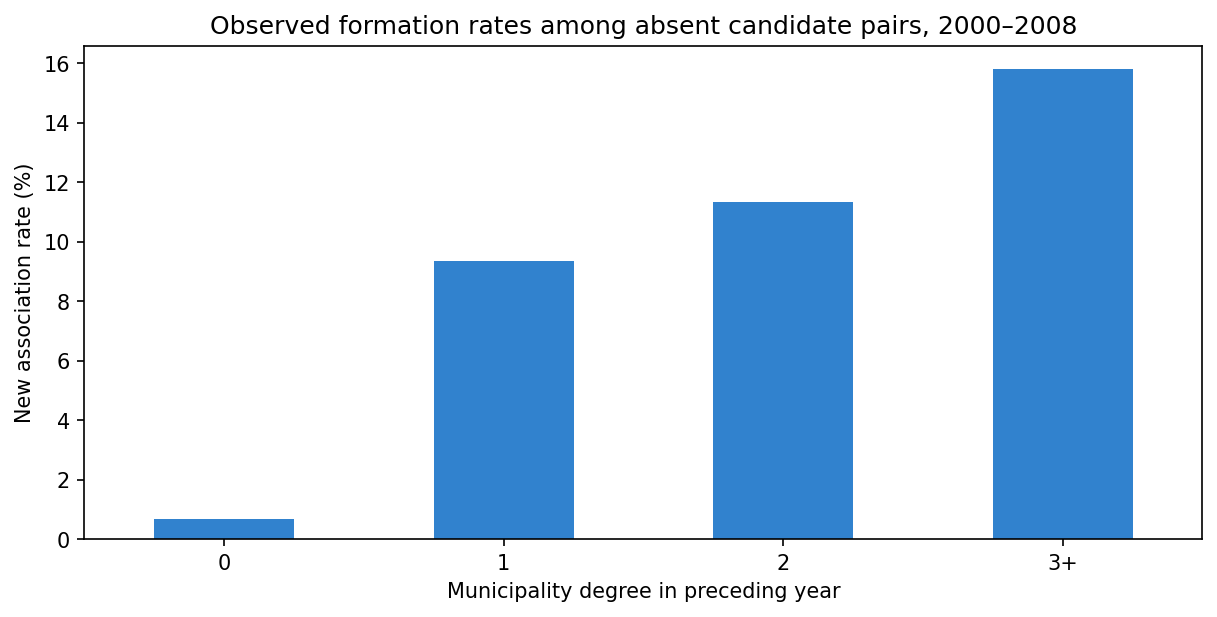

In [24]:
# Model comparison across development and final prediction years.
main_results = evaluation_results[evaluation_results["scenario"] == "Main"]
fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
for label, group in main_results.groupby("model", sort=False):
    ax.plot(group["year"], group["average_precision"], marker="o", label=label)
ax.axvspan(2008.5, 2010.3, color="gray", alpha=0.08, label="Final evaluation years")
ax.set(title="Predicting new reported associations", xlabel="Prediction year", ylabel="Average precision", xticks=[2007, 2008, 2009, 2010])
ax.legend(fontsize=8, loc="best")
ax.grid(alpha=0.2)
show_presentation_figure(fig)

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
positions = np.arange(len(effect_results))
ax.errorbar(effect_results["odds_ratio"], positions,
    xerr=np.vstack([effect_results["odds_ratio"] - effect_results["95_lower"],
                   effect_results["95_upper"] - effect_results["odds_ratio"]]), fmt="o", capsize=3)
ax.axvline(1, color="gray", linestyle="--")
ax.set(yticks=positions, yticklabels=effect_results["feature"].str.replace("_", " "),
    xlabel="Adjusted odds ratio (log scale); state-clustered 95% interval",
    title="Patterns associated with emergence — development data", xscale="log")
show_presentation_figure(fig)

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
(100 * formation_rates["formation_rate"]).plot.bar(ax=ax, color="#3182ce", rot=0)
ax.set(xlabel="Municipality degree in preceding year", ylabel="New association rate (%)",
    title="Observed formation rates among absent candidate pairs, 2000–2008")
show_presentation_figure(fig)

## Research results: Name : value

Final-year AP gains are compared with the history model using paired state-block bootstrap intervals. An interval spanning zero does not establish a clear improvement under this uncertainty calculation. Check comparisons against both degree baselines as well. Sensitivity findings and year-to-year consistency matter; a positive coefficient or predictive gain does not identify a causal mechanism.

In [25]:
for year, row in eligibility_summary.iterrows():
    for name, value in row.items(): print_presentation_value(f"Research {year} {name.replace('_', ' ')}", value)
for _, row in evaluation_results.iterrows():
    for name in ["candidates", "positives", "formation_rate", "average_precision", "precision_at_100", "recall_at_100"]:
        print_presentation_value(f"{row['scenario']} {row['year']} {row['model']} {name.replace('_', ' ')}", row[name])
for year, row in prediction_uncertainty.iterrows():
    for name, value in row.items(): print_presentation_value(f"Final {year} {name.replace('_', ' ')}", value)
for _, row in effect_results.iterrows():
    for name in ["odds_ratio", "95_lower", "95_upper"]:
        print_presentation_value(f"Development {row['feature']} {name}", row[name])
for degree, row in formation_rates.iterrows():
    for name, value in row.items(): print_presentation_value(f"Degree {degree} {name.replace('_', ' ')}", value)
print_presentation_value("Inferential model converged", association_model.converged)
print_presentation_value("Inferential state clusters", inference_data['state'].nunique())

Research 1991 eligible pairs : 0
Research 1991 new links : 0
Research 1991 positives excluded unobserved organization : 6
Research 1992 eligible pairs : 4908
Research 1992 new links : 1
Research 1992 positives excluded unobserved organization : 5
Research 1993 eligible pairs : 9822
Research 1993 new links : 19
Research 1993 positives excluded unobserved organization : 2
Research 1994 eligible pairs : 12261
Research 1994 new links : 25
Research 1994 positives excluded unobserved organization : 0
Research 1995 eligible pairs : 12254
Research 1995 new links : 15
Research 1995 positives excluded unobserved organization : 0
Research 1996 eligible pairs : 12262
Research 1996 new links : 27
Research 1996 positives excluded unobserved organization : 1
Research 1997 eligible pairs : 14706
Research 1997 new links : 41
Research 1997 positives excluded unobserved organization : 1
Research 1998 eligible pairs : 17148
Research 1998 new links : 37
Research 1998 positives excluded unobserved organizat

## H3: disappearance of existing associations

Candidates are municipality–organization pairs **present** at *t* in municipalities recorded at both *t* and *t+1*. The outcome `disappeared` is 1 when the association is absent at *t+1*. Features use year *t* only:

- `years_present`: consecutive years the association has been recorded up to *t*.
- `other_organizations`, `organization_degree`, and the same territorial features as for formation.

Analyses mirror H2: rates by rival context with state-bootstrap intervals, a state-clustered GLM on 2000–2008, and a temporal prediction test on 2009–2010 that compares a history model with the same model plus territorial features.

In [26]:
exit_frames = []
streak = np.zeros_like(matrices[years[0]])
for year in years[:-1]:
    current, following = matrices[year], matrices[year + 1]
    streak = np.where(current == 1, streak + 1, 0)
    shared_indexes = np.array([code_index[c] for c in sorted(recorded_codes[year] & recorded_codes[year + 1])])
    local_m, org = np.where(current[shared_indexes] == 1)
    if len(local_m) == 0:
        continue
    municipality = shared_indexes[local_m]
    exit_frames.append(pd.DataFrame({
        "prediction_year": year + 1,
        "municipality": [municipality_codes[i] for i in municipality],
        "organization": [organization_columns[i] for i in org],
        "disappeared": 1 - following[municipality, org],
        "years_present": streak[municipality, org],
        "organization_degree": current.sum(axis=0)[org],
    }))
exit_data = pd.concat(exit_frames, ignore_index=True)
exit_data["state"] = exit_data["municipality"].map(state_by_code)
exit_data = add_territory_features(exit_data)
exit_data["rival_context"] = rival_context(exit_data)
for feature in ["years_present", "organization_degree", "other_organizations"]:
    exit_data[f"log_{feature}"] = np.log1p(exit_data[feature])
assert not exit_data.duplicated(["prediction_year", "municipality", "organization"]).any()
assert (exit_data["years_present"] >= 1).all()

exit_summary = exit_data.groupby("prediction_year").agg(
    present_pairs=("disappeared", "size"), disappeared=("disappeared", "sum"), disappearance_rate=("disappeared", "mean"))
display(exit_summary[exit_summary.index >= 2000])
print(f"Existing pair-year observations: {len(exit_data):,}")

,present_pairs,disappeared,disappearance_rate
prediction_year,,,
2000,31,24,0.774194
2001,60,47,0.783333
2002,72,58,0.805556
2003,56,38,0.678571
2004,108,72,0.666667
2005,171,110,0.643275
2006,367,253,0.689373
2007,476,263,0.552521
2008,680,296,0.435294


Existing pair-year observations: 4,742


In [27]:
exit_window = exit_data[exit_data["prediction_year"].between(2000, 2010)]
exit_by_context = grouped_rates(exit_window, "disappeared", "rival_context")
exit_by_state_presence = grouped_rates(exit_window, "disappeared", "organization_in_state")
print("Disappearance rate by rival context, 2000–2010")
display(exit_by_context)
print("Disappearance rate by organization presence elsewhere in the state")
display(exit_by_state_presence)

exit_binary = ["organization_in_state", "avoider_present", "overlapper_present"]
exit_controls = ["log_years_present", "log_other_organizations", "log_organization_degree"]
exit_glm, exit_effects = fit_territory_glm(
    exit_data[exit_data["prediction_year"].between(2000, 2008)], "disappeared", exit_binary, exit_controls)
print("Disappearance GLM, 2000–2008")
display(exit_effects)

exit_history = ["log_years_present", "log_other_organizations", "log_organization_degree"]
exit_records = []
for target_year in [2009, 2010]:
    train = exit_data[exit_data["prediction_year"].between(2000, target_year - 1)]
    test = exit_data[exit_data["prediction_year"] == target_year].sort_values(["municipality", "organization"])
    scores = {"Constant baseline": np.zeros(len(test))}
    for label, features in [("History model", exit_history), ("History + territory", exit_history + territory_features)]:
        scores[label] = make_link_model(features).fit(train, train["disappeared"]).predict_proba(test)[:, 1]
    for label, predictions in scores.items():
        exit_records.append({"year": target_year, "model": label, "candidates": len(test),
                             "disappeared": int(test["disappeared"].sum()),
                             "average_precision": average_precision_score(test["disappeared"], predictions)})
exit_prediction = pd.DataFrame(exit_records)
display(exit_prediction.pivot(index="model", columns="year", values="average_precision"))

Disappearance rate by rival context, 2000–2010


,pairs,events,rate,ci_low,ci_high
rival_context,,,,,
no other organization,1238,640,0.516963,0.475553,0.556693
only neutral organizations,1050,485,0.461905,0.409048,0.514164
overlapping organization present,1527,572,0.374591,0.331885,0.419900
avoiding rival present,701,255,0.363766,0.320392,0.408935


Disappearance rate by organization presence elsewhere in the state


,pairs,events,rate,ci_low,ci_high
organization_in_state,,,,,
0,454,287,0.632159,0.576660,0.685600
1,4062,1665,0.409897,0.379451,0.434923


Disappearance GLM, 2000–2008


,feature,odds_ratio,95_lower,95_upper,p_value
0,organization_in_state,0.728200,0.502233,1.055833,9.426119e-02
1,avoider_present,1.010603,0.673260,1.516977,9.594081e-01
2,overlapper_present,1.008988,0.742302,1.371484,9.544386e-01
3,log_years_present,0.593799,0.528555,0.667097,1.683154e-18
4,log_other_organizations,0.849083,0.740116,0.974094,1.956887e-02
5,log_organization_degree,0.768867,0.584590,1.011233,6.009984e-02


year,2009,2010
model,,
Constant baseline,0.349911,0.289993
History + territory,0.468344,0.412700
History model,0.415178,0.368528


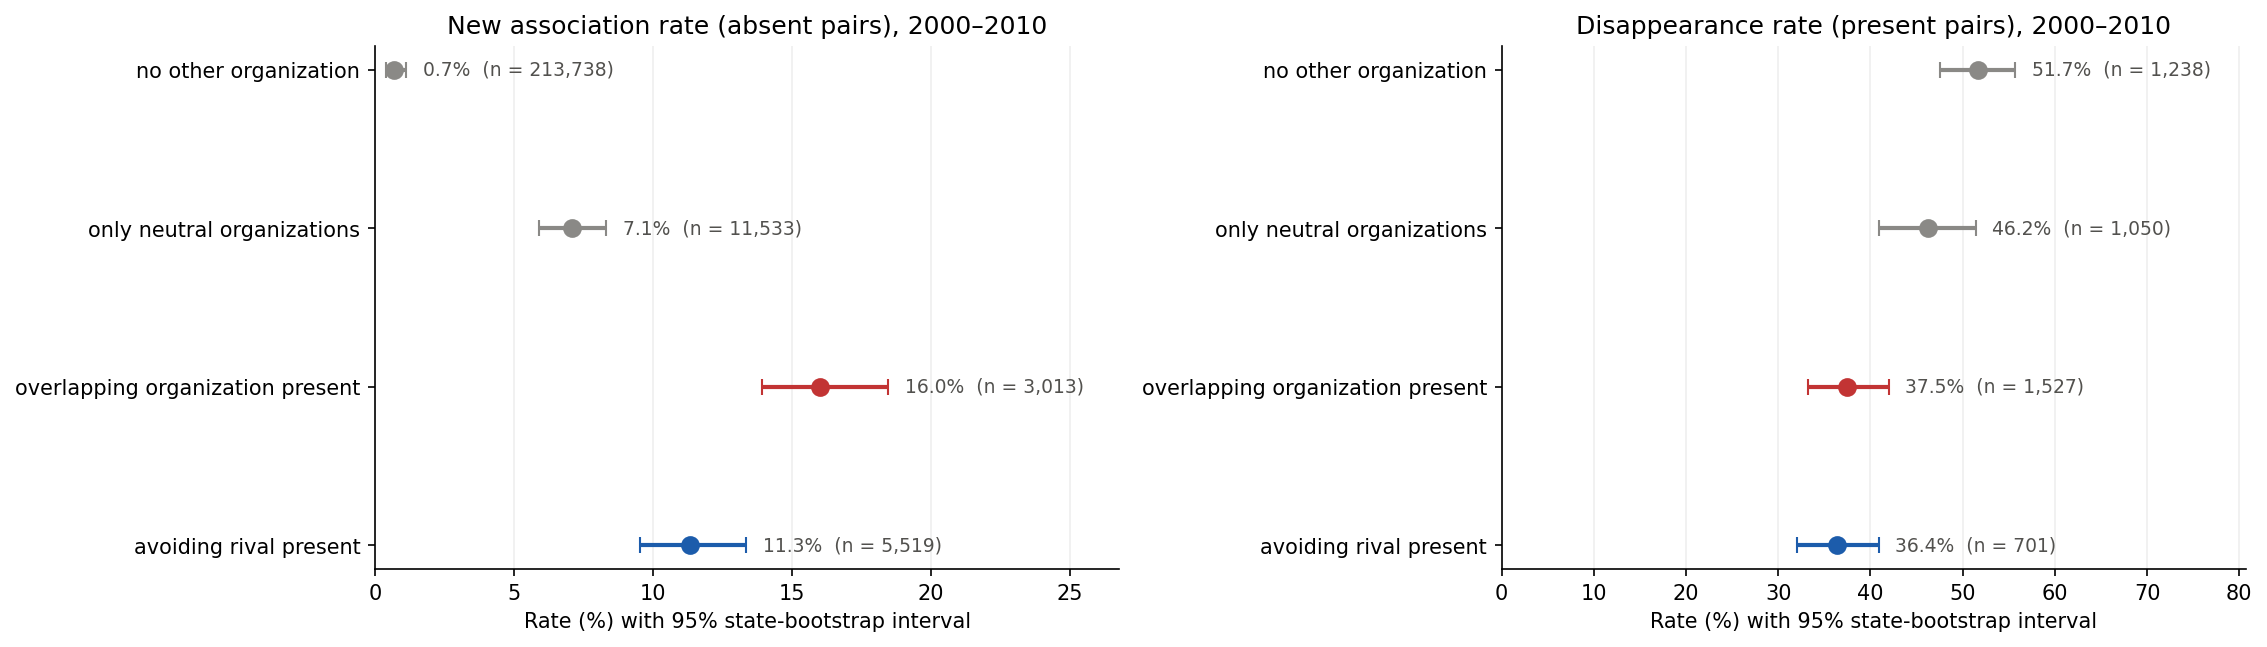

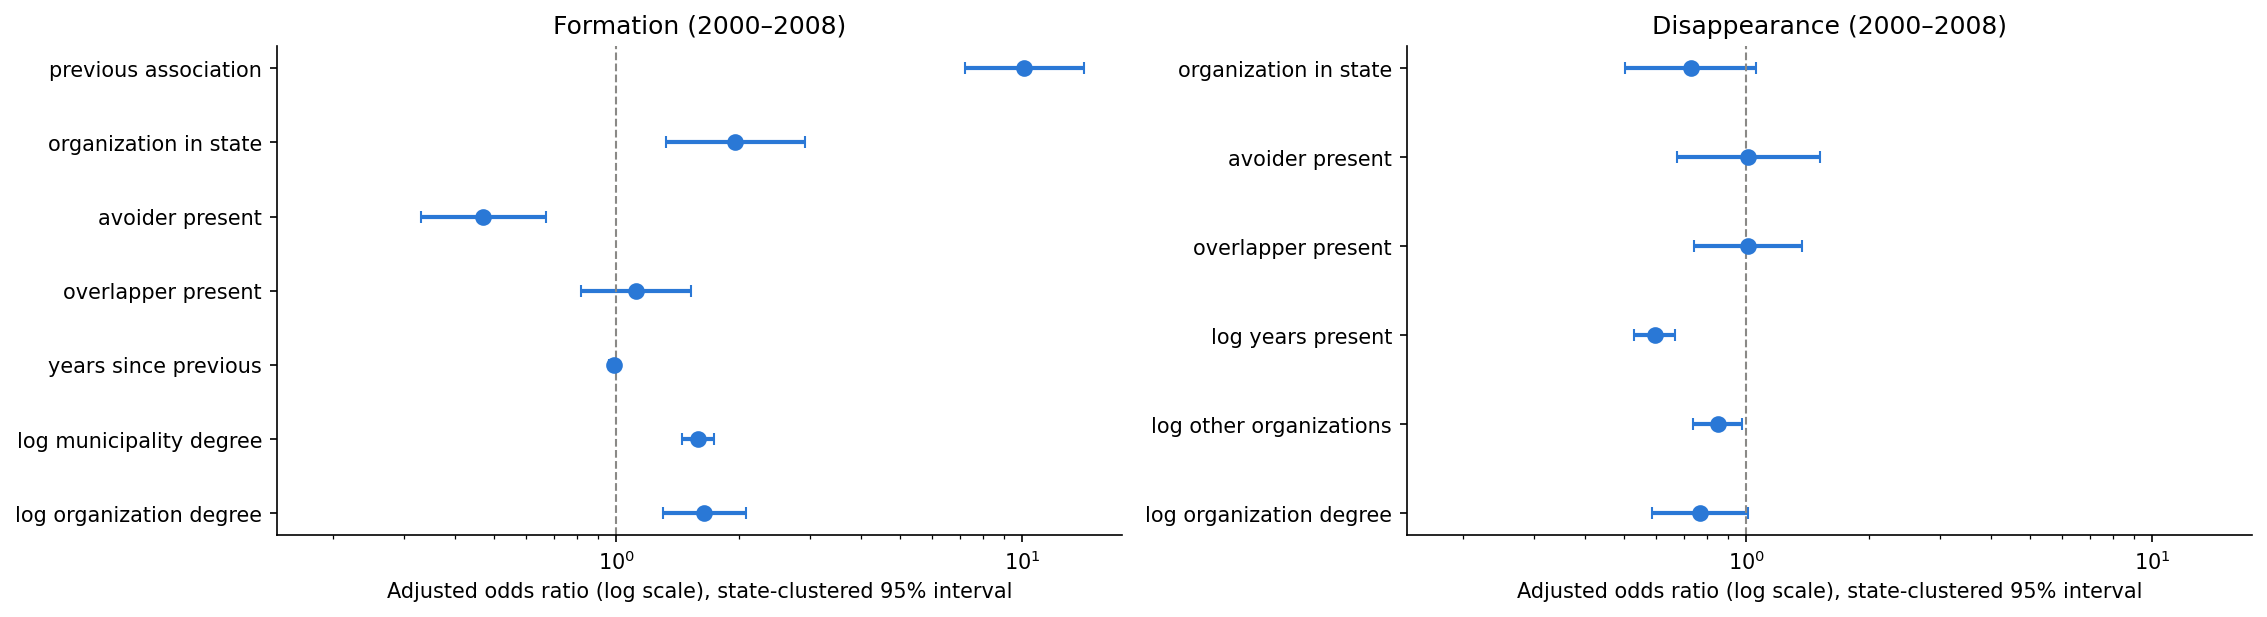

In [28]:
context_colors = {"no other organization": "#8a8986", "only neutral organizations": "#8a8986",
                  "overlapping organization present": "#c23434", "avoiding rival present": "#1c5cab"}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), constrained_layout=True)
for ax, (table, title) in zip(axes, [(formation_by_context, "New association rate (absent pairs)"),
                                     (exit_by_context, "Disappearance rate (present pairs)")]):
    positions = np.arange(len(table))[::-1]
    for y, (context, row) in zip(positions, table.iterrows()):
        ax.errorbar(100 * row["rate"], y, xerr=[[100 * (row["rate"] - row["ci_low"])], [100 * (row["ci_high"] - row["rate"])]],
                    fmt="o", ms=8, color=context_colors[context], capsize=4, lw=2)
        ax.annotate(f"{100 * row['rate']:.1f}%  (n = {int(row['pairs']):,})",(100 * row["ci_high"], y),
                    xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color="#52514e")
    ax.set_yticks(positions, table.index)
    ax.set_xlim(0, 100 * table["ci_high"].max() * 1.45)
    ax.set(title=f"{title}, 2000–2010", xlabel="Rate (%) with 95% state-bootstrap interval")
    ax.grid(axis="x", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
show_presentation_figure(fig)

fig, axes = plt.subplots(1, 2, figsize=(15, 4), constrained_layout=True, sharex=True)
for ax, (effects, title) in zip(axes, [(formation_effects, "Formation (2000–2008)"), (exit_effects, "Disappearance (2000–2008)")]):
    positions = np.arange(len(effects))[::-1]
    ax.errorbar(effects["odds_ratio"], positions,
                xerr=[effects["odds_ratio"] - effects["95_lower"], effects["95_upper"] - effects["odds_ratio"]],
                fmt="o", ms=7, color="#2a78d6", capsize=3, lw=2)
    ax.axvline(1, color="#8a8986", linestyle="--", lw=1)
    ax.set_yticks(positions, effects["feature"].str.replace("_", " "))
    ax.set(title=title, xscale="log", xlabel="Adjusted odds ratio (log scale), state-clustered 95% interval")
    ax.spines[["top", "right"]].set_visible(False)
show_presentation_figure(fig)

## H4: differences between organizations

For each organization, over prediction years 2000–2010:

- `new_associations` and `same_state_ratio`: formation rate where the organization is already in the state divided by the rate elsewhere (H1 by organization).
- `share_new_into_occupied`: share of its new associations in municipalities that already host another organization; `share_new_with_avoider`: share where an avoiding rival is present.
- `disappearance_rate` and `disappearance_rate_with_avoider`: overall and with an avoiding rival present (H3 by organization).

Organizations with fewer than 30 new associations are flagged; their ratios are unstable.

,new_associations,same_state_ratio,share_new_into_occupied,share_new_with_avoider,present_pair_years,disappearance_rate,disappearance_rate_with_avoider,pair_years_with_avoider,few_events
organization,,,,,,,,,
Zetas,823,8.363,0.433,0.203,1161,0.364,0.274,223,False
Gulf,675,3.967,0.465,0.138,1026,0.424,0.355,110,False
Sinaloa,474,3.749,0.599,0.333,651,0.461,0.414,181,False
Familia,374,10.090,0.602,0.067,416,0.353,0.571,7,False
Beltrán Leyva,363,4.347,0.683,0.264,431,0.501,0.380,108,False
Juárez,222,3.187,0.626,0.149,293,0.543,0.389,18,False
Tijuana,157,3.451,0.599,0.096,226,0.562,0.438,16,False
Otros,107,2.406,0.888,0.150,117,0.462,0.727,11,False
Sinaloa Family,101,5.911,0.881,0.000,98,0.490,NaN,0,False


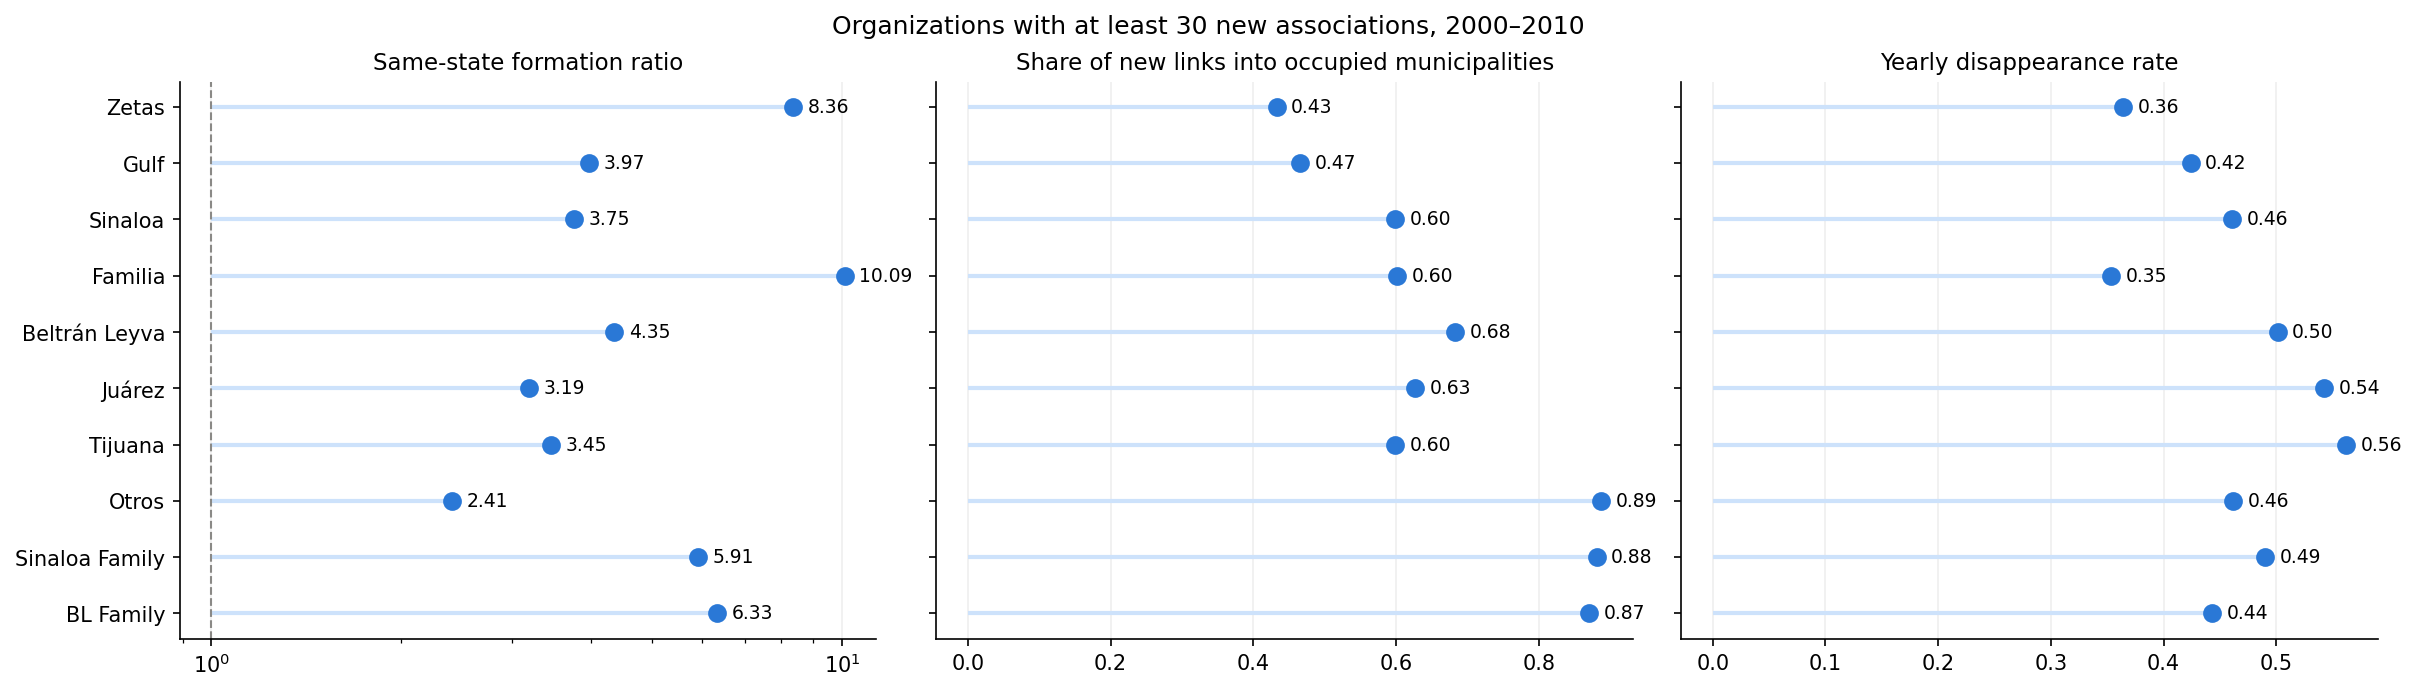

In [29]:
h4_rows = []
for organization in organization_columns:
    formed = formation_window[formation_window["organization"] == organization]
    exits = exit_window[exit_window["organization"] == organization]
    new = formed[formed["new_link"] == 1]
    in_state_rate = formed.loc[formed["organization_in_state"] == 1, "new_link"].mean()
    out_state_rate = formed.loc[formed["organization_in_state"] == 0, "new_link"].mean()
    h4_rows.append({
        "organization": display_names[organization],
        "new_associations": len(new),
        "same_state_ratio": in_state_rate / out_state_rate if out_state_rate > 0 else np.nan,
        "share_new_into_occupied": (new["other_organizations"] > 0).mean() if len(new) else np.nan,
        "share_new_with_avoider": new["avoider_present"].mean() if len(new) else np.nan,
        "present_pair_years": len(exits),
        "disappearance_rate": exits["disappeared"].mean() if len(exits) else np.nan,
        "disappearance_rate_with_avoider": exits.loc[exits["avoider_present"] == 1, "disappeared"].mean(),
        "pair_years_with_avoider": int(exits["avoider_present"].sum()),
        "few_events": len(new) < 30,
    })
organization_patterns = pd.DataFrame(h4_rows).set_index("organization").sort_values("new_associations", ascending=False)
display(organization_patterns.round(3))

reliable = organization_patterns[~organization_patterns["few_events"]]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True, sharey=True)
panels = [("same_state_ratio", "Same-state formation ratio", True),
          ("share_new_into_occupied", "Share of new links into occupied municipalities", False),
          ("disappearance_rate", "Yearly disappearance rate", False)]
positions = np.arange(len(reliable))[::-1]
for ax, (column, title, log_scale) in zip(axes, panels):
    ax.hlines(positions, 1 if log_scale else 0, reliable[column], color="#cde2fb", lw=2)
    ax.plot(reliable[column], positions, "o", ms=8, color="#2a78d6")
    for y, value in zip(positions, reliable[column]):
        ax.annotate(f"{value:.2f}", (value, y), xytext=(7, 0), textcoords="offset points", va="center", fontsize=9)
    if log_scale:
        ax.set_xscale("log")
        ax.axvline(1, color="#8a8986", linestyle="--", lw=1)
    ax.set_title(title, fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.2)
axes[0].set_yticks(positions, reliable.index)
fig.suptitle("Organizations with at least 30 new associations, 2000–2010", fontsize=12)
show_presentation_figure(fig)

## Robustness of the territorial effects

The formation and disappearance GLMs are refitted (same specification, 2000–2008) after excluding `Otros`, and the formation model also on first-observed associations only (no previous association with that municipality). Stable odds ratios across rows support the main results; large changes mark results that depend on a particular subset.

In [30]:
robust_rows = []
scenarios = [
    ("Formation", "Main", research_data, "new_link", formation_binary, formation_controls),
    ("Formation", "Exclude Otros", research_data[research_data["organization"] != "Otros"], "new_link", formation_binary, formation_controls),
    ("Formation", "First observed only", research_data[research_data["previous_association"] == 0], "new_link",
     [t for t in formation_binary if t != "previous_association"], [c for c in formation_controls if c != "years_since_previous"]),
    ("Disappearance", "Main", exit_data, "disappeared", exit_binary, exit_controls),
    ("Disappearance", "Exclude Otros", exit_data[exit_data["organization"] != "Otros"], "disappeared", exit_binary, exit_controls),
]
for outcome_name, scenario, frame, outcome, binary, controls in scenarios:
    _, effects = fit_territory_glm(frame[frame["prediction_year"].between(2000, 2008)], outcome, binary, controls)
    for _, row in effects[effects["feature"].isin(["organization_in_state", "avoider_present", "overlapper_present"])].iterrows():
        robust_rows.append({"outcome": outcome_name, "scenario": scenario, "feature": row["feature"],
                            "odds_ratio": row["odds_ratio"], "95_lower": row["95_lower"], "95_upper": row["95_upper"]})
robustness = pd.DataFrame(robust_rows)
display(robustness.pivot_table(index=["outcome", "scenario"], columns="feature", values="odds_ratio").round(2))
display(robustness.round(3))

feature                            avoider_present  organization_in_state  \
outcome       scenario                                                      
Disappearance Exclude Otros                   1.00                   0.79   
              Main                            1.01                   0.73   
Formation     Exclude Otros                   0.49                   2.01   
              First observed only             0.60                   2.00   
              Main                            0.47                   1.96   

feature                            overlapper_present  
outcome       scenario                                 
Disappearance Exclude Otros                      1.00  
              Main                               1.01  
Formation     Exclude Otros                      1.16  
              First observed only                1.37  
              Main                               1.11

,outcome,scenario,feature,odds_ratio,95_lower,95_upper
0,Formation,Main,organization_in_state,1.964,1.326,2.909
1,Formation,Main,avoider_present,0.470,0.330,0.669
2,Formation,Main,overlapper_present,1.115,0.816,1.524
3,Formation,Exclude Otros,organization_in_state,2.010,1.331,3.036
4,Formation,Exclude Otros,avoider_present,0.487,0.340,0.698
5,Formation,Exclude Otros,overlapper_present,1.160,0.826,1.628
6,Formation,First observed only,organization_in_state,1.996,1.319,3.020
7,Formation,First observed only,avoider_present,0.596,0.445,0.798
8,Formation,First observed only,overlapper_present,1.370,1.021,1.839
9,Disappearance,Main,organization_in_state,0.728,0.502,1.056


## Descriptive mesoscale view: municipality backbone and communities

The remaining sections describe the territories behind the rivalry scores. They are descriptive and are not used as predictors.

## Municipality projection and backboning

Projecting onto municipalities connects two municipalities when they share at least one organization; the weight is the number of shared organizations. Because a large organization connects all of its municipalities to each other, the naive projection is a dense "hairball" (Lecture 5).

Two backbones remove edges that are explained by node strength alone:

- **Noise-corrected (NC)** backbone, edge-centric: keeps an edge when its weight exceeds the expectation from both endpoints' strengths by more than δ = 1.64 standard deviations (≈ one-tailed p < 0.05), following Coscia & Neffke (2017).
- **Disparity filter**, node-centric: keeps an edge when it is significant (α = 0.05) for at least one endpoint's distribution of edge weights (Serrano et al. 2009).

In [31]:
def municipality_projection(records):
    matrix = records[organization_columns].to_numpy()
    weights = matrix @ matrix.T
    np.fill_diagonal(weights, 0)
    return weights.astype(float)

def noise_corrected_backbone(weights, delta=1.64):
    """Boolean matrix of edges kept by the noise-corrected backbone (Coscia & Neffke 2017)."""
    n_i = weights.sum(axis=1)
    total = weights.sum()
    i, j = np.nonzero(np.triu(weights, 1))
    n_ij, ni, nj = weights[i, j], n_i[i], n_i[j]
    kappa = total / (ni * nj)
    score = (kappa * n_ij - 1) / (kappa * n_ij + 1)
    prior_mean = ni * nj / total ** 2
    prior_var = (ni * nj * (total - ni) * (total - nj)) / (total ** 4 * (total - 1))
    alpha_prior = (prior_mean ** 2 / prior_var) * (1 - prior_mean) - prior_mean
    beta_prior = (prior_mean / prior_var) * (1 - prior_mean ** 2) - (1 - prior_mean)
    posterior = (alpha_prior + n_ij) / (alpha_prior + n_ij + total - n_ij + beta_prior)
    variance_nij = posterior * (1 - posterior) * total
    d = 1 / (ni * nj) - total * (ni + nj) / (ni * nj) ** 2
    variance_score = variance_nij * (2 * (kappa + n_ij * d) / (kappa * n_ij + 1) ** 2) ** 2
    keep = np.zeros_like(weights, dtype=bool)
    keep[i, j] = score - delta * np.sqrt(variance_score) > 0
    return keep | keep.T

def disparity_backbone(weights, alpha=0.05):
    """Boolean matrix of edges kept by the disparity filter (Serrano et al. 2009)."""
    strength = weights.sum(axis=1, keepdims=True)
    degree = (weights > 0).sum(axis=1, keepdims=True)
    share = np.divide(weights, strength, out=np.zeros_like(weights), where=strength > 0)
    with np.errstate(invalid="ignore"):
        significance = (1 - share) ** (degree - 1)
    kept_by_node = (weights > 0) & (degree > 1) & (significance < alpha)
    return kept_by_node | kept_by_node.T

def graph_from_matrix(records, weights, keep):
    graph = nx.Graph()
    codes = records["Code"].to_numpy()
    graph.add_nodes_from((code, {"state": state}) for code, state in zip(codes, records["State"]))
    i, j = np.nonzero(np.triu(keep, 1))
    graph.add_weighted_edges_from(zip(codes[i], codes[j], weights[i, j]))
    return graph

projection_rows = []
municipality_backbones = {}
for year in focus_years:
    records = active_by_year[year]
    weights = municipality_projection(records)
    naive = weights > 0
    nc = noise_corrected_backbone(weights)
    disparity = disparity_backbone(weights)
    municipality_backbones[year] = graph_from_matrix(records, weights, nc)
    n = len(records)
    projection_rows.append({
        "year": year, "municipalities": n,
        "naive_edges": int(np.triu(naive, 1).sum()),
        "naive_density": np.triu(naive, 1).sum() / (n * (n - 1) / 2),
        "nc_edges": int(np.triu(nc, 1).sum()),
        "nc_non_isolated": int(nc.any(axis=1).sum()),
        "disparity_edges": int(np.triu(disparity, 1).sum()),
        "disparity_non_isolated": int(disparity.any(axis=1).sum()),
    })
projection_summary = pd.DataFrame(projection_rows).set_index("year")
projection_summary["nc_edge_share_kept"] = projection_summary["nc_edges"] / projection_summary["naive_edges"]
display(projection_summary.round(3))

,municipalities,naive_edges,naive_density,nc_edges,nc_non_isolated,disparity_edges,disparity_non_isolated,nc_edge_share_kept
year,,,,,,,,
2006,297,17022,0.387,3926,207,4,4,0.231
2008,588,91577,0.531,11816,348,53,24,0.129
2010,709,138469,0.552,17755,398,152,52,0.128


## Communities in the municipality backbone

Louvain communities are computed on the weighted noise-corrected backbone (non-isolated municipalities only). Louvain is stochastic, so it is run with 20 seeds; the highest-modularity partition is reported together with the spread across seeds.

Agreement with state borders is measured with normalized mutual information (NMI) between community and state labels. The null distribution comes from 1,000 random permutations of the state labels over the same municipalities.

In [32]:
community_rows = []
community_profiles = {}
for year in focus_years:
    graph = municipality_backbones[year]
    graph = graph.subgraph([n for n in graph if graph.degree(n) > 0]).copy()
    runs = []
    for seed in range(20):
        partition = nx.community.louvain_communities(graph, weight="weight", seed=seed)
        runs.append((nx.community.modularity(graph, partition, weight="weight"), partition))
    modularities = [q for q, _ in runs]
    best_q, best = max(runs, key=lambda run: run[0])
    community_of = {node: k for k, members in enumerate(sorted(best, key=len, reverse=True)) for node in members}
    nodes = list(graph)
    states = np.array([graph.nodes[n]["state"] for n in nodes])
    communities = np.array([community_of[n] for n in nodes])
    observed_nmi = normalized_mutual_info_score(states, communities)
    rng = np.random.default_rng(year)
    null_nmi = np.array([normalized_mutual_info_score(rng.permutation(states), communities) for _ in range(1000)])
    community_rows.append({
        "year": year, "nodes": graph.number_of_nodes(), "edges": graph.number_of_edges(),
        "communities": len(best), "communities_10_plus": sum(len(c) >= 10 for c in best),
        "modularity_best": best_q, "modularity_min": min(modularities), "modularity_max": max(modularities),
        "nmi_with_state": observed_nmi, "nmi_null_mean": null_nmi.mean(),
        "nmi_null_p": (np.sum(null_nmi >= observed_nmi) + 1) / (len(null_nmi) + 1),
    })
    # Profile communities with at least 10 municipalities by organization share and main states.
    records = active_by_year[year].set_index("Code")
    profile_rows = []
    for k in sorted(set(communities)):
        members = [n for n in nodes if community_of[n] == k]
        if len(members) < 10:
            continue
        shares = records.loc[members, organization_columns].mean().sort_values(ascending=False)
        top_states = records.loc[members, "State"].value_counts(normalize=True).head(3)
        profile_rows.append({
            "community": k, "municipalities": len(members),
            "main organizations (share of members)": ", ".join(f"{display_names[o]} {s:.0%}" for o, s in shares.head(3).items() if s > 0),
            "main states (share of members)": ", ".join(f"{state_names[s]} {p:.0%}" for s, p in top_states.items()),
        })
    community_profiles[year] = pd.DataFrame(profile_rows).set_index("community")

community_summary = pd.DataFrame(community_rows).set_index("year")
display(community_summary.round(3))
for year in focus_years:
    print(f"\n{year} communities with at least 10 municipalities")
    display(community_profiles[year])

,nodes,edges,communities,communities_10_plus,modularity_best,modularity_min,modularity_max,nmi_with_state,nmi_null_mean,nmi_null_p
year,,,,,,,,,,
2006,207,3926,6,6,0.577,0.559,0.577,0.278,0.153,0.001
2008,348,11816,6,6,0.452,0.419,0.452,0.217,0.093,0.001
2010,398,17755,4,4,0.435,0.416,0.435,0.249,0.057,0.001



2006 communities with at least 10 municipalities


,municipalities,main organizations (share of members),main states (share of members)
community,,,
0,49,"Sinaloa 100%, Juárez 18%, Tijuana 12%","Chihuahua 14%, Michoacán 8%, Jalisco 8%"
1,39,"Beltrán Leyva 100%, Sinaloa 36%, Zetas 33%","Nuevo León 18%, México 13%, Chihuahua 10%"
2,37,Gulf 100%,"Tabasco 19%, Nuevo León 11%, Morelos 8%"
3,32,"Familia 100%, Gulf 41%, Zetas 28%","Michoacán 81%, Guanajuato 6%, Distrito Federal 3%"
4,31,"Tijuana 81%, Otros 35%, Gulf 29%","Baja California 13%, Chihuahua 13%, México 13%"
5,19,"Juárez 100%, Gulf 47%, Sinaloa 21%","Chihuahua 16%, México 16%, Nuevo León 16%"



2008 communities with at least 10 municipalities


,municipalities,main organizations (share of members),main states (share of members)
community,,,
0,105,"Beltrán Leyva 100%, Sinaloa 36%, Zetas 28%","México 13%, Sinaloa 10%, Morelos 10%"
1,84,"Sinaloa 100%, Gulf 20%, Familia 19%","Chihuahua 14%, Guerrero 10%, Jalisco 10%"
2,53,Gulf 100%,"Guanajuato 13%, Zacatecas 11%, Nuevo León 11%"
3,48,"Familia 100%, Zetas 35%, Gulf 33%","Michoacán 33%, México 29%, Guanajuato 19%"
4,36,"Tijuana 58%, Otros 58%, Zetas 47%","Baja California 14%, México 14%, Tamaulipas 14%"
5,22,"Juárez 95%, Zetas 36%, Gulf 23%","Chihuahua 55%, Coahuila 5%, Durango 5%"



2010 communities with at least 10 municipalities


,municipalities,main organizations (share of members),main states (share of members)
community,,,
0,155,"Sinaloa 85%, Juárez 43%, Zetas 35%","Chihuahua 21%, Durango 13%, Sinaloa 8%"
1,116,"Beltrán Leyva 97%, Familia 31%, BL Family 29%","Morelos 17%, Guerrero 16%, México 16%"
2,104,"Familia 100%, Gulf 16%, Sinaloa 13%","Michoacán 45%, Guanajuato 12%, México 11%"
3,23,"Gulf 100%, Zetas 13%, Otros 13%","Zacatecas 26%, Tamaulipas 13%, Coahuila 9%"


## Territorial analysis results: Name : value

In [33]:
print_presentation_value("Overlap null samples per year and null model", null_samples)
print_presentation_value("Bonferroni critical |z|", critical_z)
print_presentation_value("Feature cut-off |z|", feature_z)
for _, row in pair_table[pair_table["significant_after_state_control"]].iterrows():
    print_presentation_value(f"{row['year']} {row['pair']} state-null z", row["z_state_null"])
    print_presentation_value(f"{row['year']} {row['pair']} degree-null z", row["z_degree_null"])
    print_presentation_value(f"{row['year']} {row['pair']} shared municipalities", row["shared_municipalities"])
for year, row in network_over_time.iterrows():
    for name, value in row.items():
        print_presentation_value(f"{year} {name.replace('_', ' ')}", value)
for analysis, row in expansion_summary.iterrows():
    for name, value in row.items():
        print_presentation_value(f"H1 expansion ({analysis}) {name.replace('_', ' ')}", value)
for label, table in [("Formation", formation_by_context), ("Disappearance", exit_by_context),
                     ("Formation by state presence", formation_by_state_presence),
                     ("Disappearance by state presence", exit_by_state_presence)]:
    for group, row in table.iterrows():
        for name, value in row.items():
            print_presentation_value(f"{label} [{group}] {name.replace('_', ' ')}", value)
for label, effects in [("Formation GLM", formation_effects), ("Disappearance GLM", exit_effects)]:
    for _, row in effects.iterrows():
        for name in ["odds_ratio", "95_lower", "95_upper", "p_value"]:
            print_presentation_value(f"{label} {row['feature']} {name}", row[name])
for _, row in exit_prediction.iterrows():
    print_presentation_value(f"Disappearance {row['year']} {row['model']} average precision", row["average_precision"])
for organization, row in organization_patterns.iterrows():
    for name, value in row.items():
        print_presentation_value(f"{organization} {name.replace('_', ' ')}", value)
for _, row in robustness.iterrows():
    print_presentation_value(f"Robustness {row['outcome']} {row['scenario']} {row['feature']} odds ratio", row["odds_ratio"])
for year, row in projection_summary.iterrows():
    for name, value in row.items():
        print_presentation_value(f"{year} municipality projection {name.replace('_', ' ')}", value)
for year, row in community_summary.iterrows():
    for name, value in row.items():
        print_presentation_value(f"{year} backbone {name.replace('_', ' ')}", value)

Overlap null samples per year and null model : 300
Bonferroni critical |z| : 3.26077
Feature cut-off |z| : 1.95996
2006 BL Family – Sinaloa Family state-null z : 3.64496
2006 BL Family – Sinaloa Family degree-null z : 4.5198
2006 BL Family – Sinaloa Family shared municipalities : 1
2006 Juárez – Sinaloa state-null z : 3.51903
2006 Juárez – Sinaloa degree-null z : 3.41421
2006 Juárez – Sinaloa shared municipalities : 13
2006 Sinaloa – Zetas state-null z : -4.30238
2006 Sinaloa – Zetas degree-null z : -4.11698
2006 Sinaloa – Zetas shared municipalities : 8
2008 Beltrán Leyva – BL Family state-null z : 3.34373
2008 Beltrán Leyva – BL Family degree-null z : 5.41896
2008 Beltrán Leyva – BL Family shared municipalities : 18
2008 Beltrán Leyva – Zetas state-null z : -3.50062
2008 Beltrán Leyva – Zetas degree-null z : -4.54595
2008 Beltrán Leyva – Zetas shared municipalities : 32
2008 Sinaloa – Zetas state-null z : -4.49508
2008 Sinaloa – Zetas degree-null z : -5.80693
2008 Sinaloa – Zetas sha

# Interpretation

**Answer to the research question:** rival presence predicts where new associations **form**, but not where existing ones **disappear**.

**H1 (path dependence): supported.**
- New associations are 5.2 times more likely where the organization is already present elsewhere in the same state (3.3% vs 0.6% of candidate pairs; 95% state-bootstrap interval 3.4–7.6). The ratio exceeds 2.4 in every year from 2002 to 2010, and 79% of new associations occur in such states. Excluding `Otros` gives the same ratio.
- The effect remains after adjusting for history, degrees, organization and year: odds ratio 1.96 (1.33–2.91). It holds for every organization, from 2.4 (`Otros`) to 10.1 (Familia).

**H2 (rival deterrence): supported.**
- Occupied municipalities attract new associations far more than empty ones (7.1–16.0% vs 0.7%): activity draws more activity.
- Among occupied municipalities, an avoiding rival lowers the chance of entry. The adjusted odds ratio is 0.47 (0.33–0.67). It is stable when `Otros` is excluded (0.49) and for first-observed associations only (0.60, 0.45–0.80). Raw rates: 11.3% with an avoiding rival vs 16.0% with an overlapping organization.
- An overlapping organization has no clear effect in the main model (1.11, 0.82–1.52); for first-observed associations it is positive (1.37, 1.02–1.84).
- Territorial features improve prediction. History + territory raises average precision over the history model by +0.084 in 2009 (0.051–0.118) and +0.038 in 2010 (0.001–0.070). Both intervals exclude zero, unlike the generic structural features (+0.031 and −0.008, intervals include zero). Who is already there matters more than general network position.

**H3 (displacement): not supported.**
- An avoiding rival does not raise the odds of disappearance (adjusted odds ratio 1.01, 0.67–1.52; same without `Otros`). In raw rates, associations disappear *less* often where an avoiding rival is present (36.4%) than where no other organization is present (51.7%).
- Disappearance is driven by persistence: each standard deviation more of consecutive years present lowers the odds (0.59, 0.53–0.67). Disappearance rates fall from about 77% in 2000 to 29% in 2010 as recording becomes denser, so many early "disappearances" are likely reporting gaps.
- Presence elsewhere in the state lowers raw disappearance (41.0% vs 63.2%), but the adjusted effect is uncertain (0.73, 0.50–1.06). Territorial features still improve the ranking of disappearances (average precision 0.415 → 0.468 in 2009, 0.369 → 0.413 in 2010; no interval computed).

**H4 (heterogeneity): partly supported.**
- Familia (10.1) and Zetas (8.4) expand most strongly within states where they already operate; Juárez (3.2), Sinaloa (3.7) and Tijuana (3.5) the least.
- Zetas and Gulf more often enter municipalities with no other organization (43–47% of their new associations go into occupied municipalities, vs 68% for Beltrán Leyva and 87–89% for the small categories). Sinaloa enters municipalities with an avoiding rival most often (33% of its new associations).
- For the organizations with enough cases (Zetas, Gulf, Sinaloa, Beltrán Leyva: 108–223 pair-years with an avoiding rival), disappearance is lower with an avoiding rival than overall, the opposite of displacement. Smaller groups (Familia: 7 pair-years) are too small to interpret.

**Supporting findings.**
- The choice of null model matters: Gulf–Zetas overlap (z = 8.8 against the degree-only null in 2010) is explained by shared states (2.4 against the state-stratified null). Zetas avoidance of Sinaloa holds in all three focus years under both nulls.
- Over time, all ten categories become active, the share of active municipalities with two or more organizations rises from about 0.1 to 0.6, and concentration (HHI) falls from 0.29 in 2000 to 0.16 in 2010. The recorded landscape becomes more crowded and less concentrated, but the fixed category list cannot show genuine fragmentation.

**Limits.** Outcomes are recorded associations from web reports, so reporting intensity can create or remove links. The state is a coarse stand-in for geography. Rivalry scores are themselves estimated from the same network. All results are conditional associations with state-clustered uncertainty, not causal effects.